# Imports

In [1]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import random
random.seed(42)

# Verify Alignment of S1 and S2 images

In [14]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

In [15]:
s2_path = "data/realigned_images/2019_dry_aligned.tif"
s1_path = "data/realigned_images/2019_S1_SAR_VV_VH.tif"

s2_src = rasterio.open(s2_path)
s1_src = rasterio.open(s1_path)

print("S2 shape:", (s2_src.count, s2_src.height, s2_src.width))
print("S1 shape:", (s1_src.count, s1_src.height, s1_src.width))

print("S2 CRS:", s2_src.crs)
print("S1 CRS:", s1_src.crs)

print("S2 transform:", s2_src.transform)
print("S1 transform:", s1_src.transform)

S2 shape: (6, 51867, 70964)
S1 shape: (2, 51867, 70964)
S2 CRS: EPSG:32628
S1 CRS: EPSG:32628
S2 transform: | 9.99, 0.00, 191776.60|
| 0.00,-9.99, 1859196.30|
| 0.00, 0.00, 1.00|
S1 transform: | 9.99, 0.00, 191776.60|
| 0.00,-9.99, 1859196.30|
| 0.00, 0.00, 1.00|


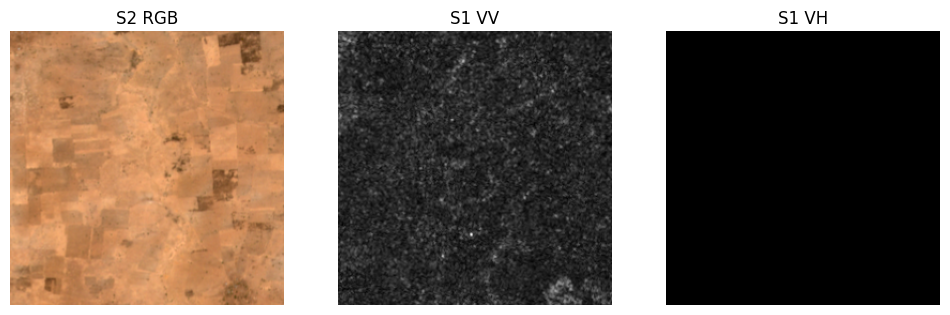

In [ ]:
# Read small window from center
row = s2_src.height // 2
col = s2_src.width // 2
size = 256

window = rasterio.windows.Window(col, row, size, size)

s2_patch = s2_src.read(window=window).astype(np.float32)
s1_patch = s1_src.read(window=window).astype(np.float32)

fig, axs = plt.subplots(1,2, figsize=(12,4))

# S2 RGB
rgb = np.transpose(s2_patch[:3], (1,2,0))
rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)

axs[0].imshow(rgb)
axs[0].set_title("S2 RGB")

axs[1].imshow(s1_patch[0], cmap="gray")
axs[1].set_title("S1")

for ax in axs:
    ax.axis("off")

plt.show()

# Patch Extraction

In [31]:
import os
import numpy as np
import rasterio
from rasterio.windows import Window
from tqdm import tqdm

In [32]:
# Paths
S2_PATH = "data/realigned_images/2019_dry_aligned.tif"
S1_PATH = "data/realigned_images/2019_S1_SAR_VV_VH.tif"
LULC_2019_PATH = "data/lulc/senegal_esri_lulc_2019.tif"

OUT_DIR = "data/mae_patches_all"
os.makedirs(OUT_DIR, exist_ok=True)

BLOCK_ROWS = 512
PATCH_SIZE = 64
STRIDE = 32
URBAN_CLASS = 7

In [33]:
with rasterio.open(S2_PATH) as s2_src, rasterio.open(S1_PATH) as s1_src:
    assert s2_src.crs == s1_src.crs, "CRS mismatch"
    assert s2_src.transform == s1_src.transform, "Transform mismatch"
    assert s2_src.width == s1_src.width, "Width mismatch"
    assert s2_src.height == s1_src.height, "Height mismatch"

    print("Alignment check passed.")
    print("Image size:", s2_src.height, "x", s2_src.width)
    print("S2 bands:", s2_src.count)
    print("S1 bands:", s1_src.count)

Alignment check passed.
Image size: 51867 x 70964
S2 bands: 6
S1 bands: 2


In [ ]:
def extract_mixmae_patches_from_block(
    s2_block,
    s1_block,
    lulc_2019_block,
    patch_size,
    stride,
    global_row_offset,
    saved_counter
):
    """
    Extracts the patches from the given block.
    Non-urban patches are randomly key with a 5% probability to balance the dataset 
    and allow our MAE to learn on both urban and non-urban patches.
    """

    H, W, _ = s2_block.shape

    for r in range(0, H - patch_size + 1, stride):
        for c in range(0, W - patch_size + 1, stride):
            lulc_2019_patch = lulc_2019_block[r:r+patch_size, c:c+patch_size]

            # Classify this patch, and randomly keep non-urban patches
            is_urban = np.any(lulc_2019_patch == URBAN_CLASS)
            if not is_urban:
                NON_URBAN_KEEP_PROB = 0.05
                if random.random() > NON_URBAN_KEEP_PROB:
                    continue
            
            s2_patch = s2_block[r:r+patch_size, c:c+patch_size, :]
            s1_patch = s1_block[r:r+patch_size, c:c+patch_size, :]

            # Channel first
            patch = np.concatenate([
                np.transpose(s2_patch, (2, 0, 1)),
                np.transpose(s1_patch, (2, 0, 1)),
            ], axis=0)

            assert patch.shape[0] == 5

            out_path = os.path.join(
                OUT_DIR,
                f"patch_r{global_row_offset+r}_c{c}.npz"
            )

            np.savez_compressed(out_path, image=patch)
            saved_counter += 1

    return saved_counter

In [ ]:
def extract_mixmae_blockwise(
    s2_path,
    s1_path,
    lulc_2019_path,
    patch_size,
    stride,
    block_rows
):

    saved = 0

    with rasterio.open(s2_path) as s2_ds, \
         rasterio.open(s1_path) as s1_ds, \
         rasterio.open(lulc_2019_path) as lulc_ds_2019:

        H, W = s2_ds.height, s2_ds.width

        assert s2_ds.count >= 4
        assert s1_ds.count >= 2

        print(f"Raster size: {H} x {W}")
        print("Starting MixMAE blockwise extraction...")

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)

            win = Window(
                col_off=0,
                row_off=row0,
                width=W,
                height=row1 - row0
            )

            # READ S2 bands 1–4
            s2_block = np.stack(
                [s2_ds.read(b, window=win) for b in (1,2,3,4)],
                axis=-1
            ).astype(np.float32)

            # Convert to actual reflectance (since BOA_QUANTIFICATION_VALUE=10000 in metadata)
            s2_block /= 10000.0

            # S1 first channel only since second channel is empty
            s1_vv = s1_ds.read(1, window=win).astype(np.float32)
            # Expand dims to keep shape so slicing works later
            s1_block = np.expand_dims(s1_vv, axis=-1)

            # Convert SAR to dB
            s1_block = 10 * np.log10(s1_block + 1e-6)

            lulc_2019_block = lulc_ds_2019.read(1, window=win)

            saved = extract_mixmae_patches_from_block(
                s2_block,
                s1_block,
                lulc_2019_block,
                patch_size,
                stride,
                global_row_offset=row0,
                saved_counter=saved
            )

    print(f"\nSaved {saved} MixMAE patches to {OUT_DIR}")

In [36]:
extract_mixmae_blockwise(
    s2_path=S2_PATH,
    s1_path=S1_PATH,
    lulc_2019_path=LULC_2019_PATH,
    patch_size=PATCH_SIZE,
    stride=STRIDE,
    block_rows=BLOCK_ROWS
)

Raster size: 51867 x 70964
Starting MixMAE blockwise extraction...



Saved 307220 MixMAE patches to data/mae_patches_all


In [ ]:
def sort_patches_by_urban_ratio():

    patch_ratios = []

    with rasterio.open(LULC_2019_PATH) as lulc_ds:

        for fname in tqdm(os.listdir(OUT_DIR)):
            if not fname.endswith(".npz"):
                continue

            # Parse coordinates from filename
            parts = fname.replace(".npz", "").split("_")
            row = int(parts[1][1:]) # rXXXX
            col = int(parts[2][1:]) # cYYYY

            # Read matching LULC window
            lulc_patch = lulc_ds.read(
                1,
                window=rasterio.windows.Window(
                    col_off=col,
                    row_off=row,
                    width=PATCH_SIZE,
                    height=PATCH_SIZE
                )
            )

            urban_ratio = np.mean(lulc_patch == URBAN_CLASS)

            patch_ratios.append((fname, urban_ratio))

    # Sort descending (most urban first)
    patch_ratios.sort(key=lambda x: x[1], reverse=True)

    print("\nTop 10 most urban patches:")
    for p in patch_ratios[:10]:
        print(p)

    return patch_ratios

In [38]:
sorted_patches = sort_patches_by_urban_ratio()
print(sorted_patches[2])


Top 10 most urban patches:
('patch_r10208_c46976.npz', np.float64(1.0))
('patch_r10208_c47008.npz', np.float64(1.0))
('patch_r11072_c47936.npz', np.float64(1.0))
('patch_r11456_c47360.npz', np.float64(1.0))
('patch_r11456_c47392.npz', np.float64(1.0))
('patch_r11488_c47360.npz', np.float64(1.0))
('patch_r12576_c18848.npz', np.float64(1.0))
('patch_r12704_c49504.npz', np.float64(1.0))
('patch_r12800_c49536.npz', np.float64(1.0))
('patch_r12960_c17664.npz', np.float64(1.0))
('patch_r11072_c47936.npz', np.float64(1.0))


In [ ]:
def normalise_rgb(img_chw):
    """
    img_chw: (3, H, W)
    returns: (H, W, 3) in [0,1]
    """
    rgb = np.stack([img_chw[0], img_chw[1], img_chw[2]], axis=-1)
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
    return rgb

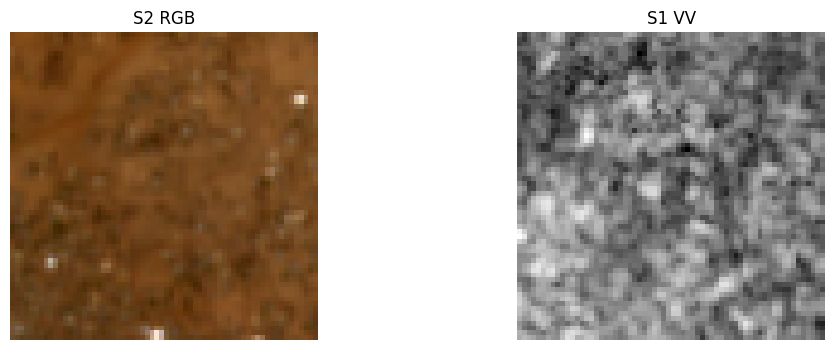

In [ ]:
import matplotlib.pyplot as plt

patch_path = os.path.join(OUT_DIR, sorted_patches[4][0])
data = np.load(patch_path)
img = data["image"]

rgb = normalise_rgb(img[0:3]) 
rest = img[3:]
vv = img[4]

fig, axs = plt.subplots(1,2, figsize=(12,4))

axs[0].imshow(rgb)
axs[0].set_title("S2 RGB")

axs[1].imshow(vv, cmap="gray")
axs[1].set_title("S1 VV")

for ax in axs:
    ax.axis("off")

plt.show()

In [ ]:
import os
import glob
import numpy as np
from tqdm import tqdm

MAE_PATCH_DIR = "data/mae_patches_all"
NUM_SAMPLES = 2000 # Number of patches to sample for statistics

def find_dataset_stats(patch_dir, num_samples=2000):
    patch_paths = glob.glob(os.path.join(patch_dir, "*.npz"))
    if len(patch_paths) == 0:
        print("No patches found!")
        return
    
    # Shuffle to get a random distribution
    np.random.shuffle(patch_paths)
    sample_paths = patch_paths[:num_samples]

    s2_mins, s2_maxs = [], []
    s1_mins, s1_maxs = [], []

    print(f"Analyzing {num_samples} patches...")
    for fpath in tqdm(sample_paths):
        with np.load(fpath) as data:
            img = data["image"] # Shape: (5, H, W)
            
            s2_data = img[:4] # Channels 0-3
            s1_data = img[4]  # Channel 4 (VV)

            s2_mins.append(np.min(s2_data))
            s2_maxs.append(np.max(s2_data))
            s1_mins.append(np.min(s1_data))
            s1_maxs.append(np.max(s1_data))

    print("\n" + "="*30)
    print("SENTINEL-2 STATS (Reflectance)")
    print(f"Absolute Min: {np.min(s2_mins):.4f}")
    print(f"Absolute Max: {np.max(s2_maxs):.4f}")
    print(f"Suggested Clip: [0.0, 1.0]") # Usually reflectance stays here
    
    print("\nSENTINEL-1 STATS (VV dB)")
    print(f"Absolute Min: {np.min(s1_mins):.4f}")
    print(f"Absolute Max: {np.max(s1_maxs):.4f}")
    
    # Calculate more robust stats
    s1_flattened = np.array(s1_mins)
    print(f"95th Percentile Min: {np.percentile(s1_mins, 5):.2f}")
    print(f"95th Percentile Max: {np.percentile(s1_maxs, 95):.2f}")
    print("="*30)

find_dataset_stats(MAE_PATCH_DIR, num_samples=NUM_SAMPLES)

Analyzing 2000 patches...



SENTINEL-2 STATS (Reflectance)
Absolute Min: 0.0000
Absolute Max: 2.2347
Suggested Clip: [0.0, 1.0]

SENTINEL-1 STATS (VV dB)
Absolute Min: -60.0000
Absolute Max: 34.2111
95th Percentile Min: -60.00
95th Percentile Max: 24.56


# MixMAE Implementation (Failed)

In [ ]:
class MixMAEDataset(Dataset):
    def __init__(self, patch_paths):
        self.paths = patch_paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = np.load(self.paths[idx])["image"].astype(np.float32)
        s2  = torch.tensor(img[:4])
        s1  = torch.tensor(img[4:])
        return s2, s1

In [ ]:
class DualPatchEmbed(nn.Module):
    """
    Two independent patch-projection heads (one per modality).
    """

    def __init__(self, embed_dim: int = 256, patch_size: int = 8):
        super().__init__()
        # Pass the imgs into Entry NNs to get the embeddings
        self.s2_embed = nn.Conv2d(4, embed_dim, patch_size, patch_size)
        self.s1_embed = nn.Conv2d(2, embed_dim, patch_size, patch_size)

    def forward(self, s2: torch.Tensor, s1: torch.Tensor):
        s2_tokens = self.s2_embed(s2).flatten(2).transpose(1, 2)  # (B, N, D)
        s1_tokens = self.s1_embed(s1).flatten(2).transpose(1, 2)  # (B, N, D)
        return s2_tokens, s1_tokens

In [4]:
def patchify(img: torch.Tensor, patch_size: int) -> torch.Tensor:
    B, C, H, W = img.shape
    assert H % patch_size == 0 and W % patch_size == 0
    h, w = H // patch_size, W // patch_size
    x = img.reshape(B, C, h, patch_size, w, patch_size)
    x = x.permute(0, 2, 4, 3, 5, 1)
    x = x.reshape(B, h * w, patch_size * patch_size * C)
    return x

In [5]:
def mix_embeddings(
    s2_tokens: torch.Tensor,
    s1_tokens: torch.Tensor,
    k: int | None = None,
):
    """
    Randomly sample k embeddings from S2 and (N-k) from S1
    to form the mixed input sequence. (k = N/2)
    """
    B, N, D = s2_tokens.shape
    if k is None:
        k = N // 2

    # Random shuffle per sample
    noise = torch.rand(B, N, device=s2_tokens.device)
    ids_shuffle = torch.argsort(noise, dim=1)
    ids_restore = torch.argsort(ids_shuffle, dim=1)

    # For the first k take from S2, then take the rest from S1
    ids_s2 = ids_shuffle[:, :k]
    ids_s1 = ids_shuffle[:, k:]

    s2_kept = torch.gather(
        s2_tokens, 1, ids_s2.unsqueeze(-1).expand(-1, -1, D)
    )

    s1_kept = torch.gather(
        s1_tokens, 1, ids_s1.unsqueeze(-1).expand(-1, -1, D)
    )

    # Concatenate in shuffled order, then restore original patch order
    mixed_shuffled = torch.cat([s2_kept, s1_kept], dim=1)
    mixed = torch.gather(
        mixed_shuffled, 1, ids_restore.unsqueeze(-1).expand(-1, -1, D)
    )

    # Build masks
    s2_mask = torch.ones(B, N, dtype=torch.bool, device=s2_tokens.device)

    s2_mask.scatter_(1, ids_s2, False)

    s1_mask = torch.ones(B, N, dtype=torch.bool, device=s1_tokens.device)
    s1_mask.scatter_(1, ids_s1, False)

    return mixed, s2_mask, s1_mask


In [6]:
class MixMAE(nn.Module):

    def __init__(
        self,
        embed_dim: int = 256,
        depth: int = 6,
        num_heads: int = 8,
        mlp_ratio: float = 2.0,
        patch_size: int = 8,
        lam: float = 0.5,
    ):
        super().__init__()
        self.embed_dim  = embed_dim
        self.patch_size = patch_size
        self.lam = lam

        self.patch_embed = DualPatchEmbed(embed_dim, patch_size)

        # Pos embedding will be initialised on first forward pass
        self.pos_embed = None

        # Shared transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=int(embed_dim * mlp_ratio),
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=depth,
            norm=nn.LayerNorm(embed_dim),
        )

        self.s2_decoder = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, patch_size * patch_size * 4),
        )
        self.s1_decoder = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, patch_size * patch_size * 2),
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def _get_pos_embed(self, N: int, device):
        """Lazily initialise and cache a sinusoidal positional embedding."""
        if self.pos_embed is None or self.pos_embed.shape[1] != N:
            pe = torch.zeros(1, N, self.embed_dim, device=device)
            pos = torch.arange(N, device=device).unsqueeze(1).float()
            div = torch.exp(
                torch.arange(0, self.embed_dim, 2, device=device).float()
                * (-np.log(10000.0) / self.embed_dim)
            )
            pe[0, :, 0::2] = torch.sin(pos * div)
            pe[0, :, 1::2] = torch.cos(pos * div)
            self.pos_embed = pe.detach()
        return self.pos_embed

    def forward(self, s2: torch.Tensor, s1: torch.Tensor):
        # Embed each modality independently
        s2_tokens, s1_tokens = self.patch_embed(s2, s1)
        B, N, D = s2_tokens.shape

        # Add positional embeddings before mixing
        pe = self._get_pos_embed(N, s2_tokens.device)
        s2_tokens = s2_tokens + pe
        s1_tokens = s1_tokens + pe

        # Randomly swap k=N/2 token positions between s1 and s2
        mixed, s2_mask, s1_mask = mix_embeddings(s2_tokens, s1_tokens)

        # Shared encoder
        encoded = self.encoder(mixed)

        # Individual and separate decoders
        s2_pred = self.s2_decoder(encoded)
        s1_pred = self.s1_decoder(encoded)

        return s2_pred, s1_pred, s2_mask, s1_mask

In [7]:
def reconstruction_loss(
    pred: torch.Tensor,
    target: torch.Tensor,
    mask: torch.Tensor,
    lam: float = 1.0,
) -> torch.Tensor:
    """
    MSE loss computed only on the masked patches.
    """
    # Expand mask to match prediction dimensions
    mask_expanded = mask.unsqueeze(-1).expand_as(pred) 

    # Compute element-wise squared error only on masked positions
    loss = F.mse_loss(pred[mask_expanded], target[mask_expanded])
    return lam * loss


def total_mixmae_loss(
    s2_pred: torch.Tensor, s1_pred: torch.Tensor,
    s2_target: torch.Tensor, s1_target: torch.Tensor,
    s2_mask: torch.Tensor, s1_mask: torch.Tensor,
    lam: float = 0.5,
) -> torch.Tensor:
    """
    Calculates the total loss for both the s1 and s2 reconstructions
    """
    l_s2 = reconstruction_loss(s2_pred, s2_target, s2_mask, lam=1.0 - lam)
    l_s1 = reconstruction_loss(s1_pred, s1_target, s1_mask, lam=lam)
    return l_s2 + l_s1

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

PATCH_SIZE_MODEL = 8
EMBED_DIM = 256
DEPTH = 6
NUM_HEADS= 8
EPOCHS = 200
BATCH_SIZE = 128
LR = 1e-4
WEIGHT_DECAY = 1e-4

# Dataset & DataLoader 
all_patch_paths = glob.glob(os.path.join(OUT_DIR, "*.npz"))
print(f"Found {len(all_patch_paths)} patches")

# Shuffle and split
import random
random.seed(42)
random.shuffle(all_patch_paths)

split = int(0.9 * len(all_patch_paths))
train_paths = all_patch_paths[:split]
val_paths = all_patch_paths[split:]
print(f"Train: {len(train_paths)} | Val: {len(val_paths)}")

train_dataset = MixMAEDataset(train_paths)
val_dataset   = MixMAEDataset(val_paths)

loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)

# Model
model = MixMAE(
    embed_dim=EMBED_DIM,
    depth=DEPTH,
    num_heads=NUM_HEADS,
    patch_size=PATCH_SIZE_MODEL,
    lam=0.5,
).to(device)

print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

# Optimiser
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY
)

# Optional cosine LR schedule
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

# Training 
best_val_loss = float("inf")

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for s2, s1 in tqdm(loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        s2 = s2.to(device)
        s1 = s1.to(device)
        optimizer.zero_grad()
        s2_pred, s1_pred, s2_mask, s1_mask = model(s2, s1)
        s2_target = patchify(s2, PATCH_SIZE_MODEL)
        s1_target = patchify(s1, PATCH_SIZE_MODEL)
        loss = total_mixmae_loss(
            s2_pred, s1_pred,
            s2_target, s1_target,
            s2_mask, s1_mask,
            lam=0.5,
        )
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_train_loss = total_loss / len(loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for s2, s1 in val_loader:
            s2 = s2.to(device)
            s1 = s1.to(device)
            s2_pred, s1_pred, s2_mask, s1_mask = model(s2, s1)
            s2_target = patchify(s2, PATCH_SIZE_MODEL)
            s1_target = patchify(s1, PATCH_SIZE_MODEL)
            loss = total_mixmae_loss(
                s2_pred, s1_pred,
                s2_target, s1_target,
                s2_mask, s1_mask,
                lam=0.5,
            )
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    scheduler.step()

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    
    print(f"Epoch {epoch+1:3d} | Train: {avg_train_loss:.6f} "
          f"| Val: {avg_val_loss:.6f} "
          f"| LR: {scheduler.get_last_lr()[0]:.2e}")

    # Save best checkpoint depending on val loss
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "train_loss": avg_train_loss,
            "val_loss":  avg_val_loss,
        }, "mixmae_8_all_best.pt")
        print(f" => Best model saved (val loss: {best_val_loss:.6f})")

print("Training complete.")

Using device: cuda
Found 200397 patches
Train: 180357 | Val: 20040


Model parameters: 3,361,664


Epoch   1 | Train: 223.621474 | Val: 25.241163 | LR: 1.00e-04
 => Best model saved (val loss: 25.241163)


Epoch   2 | Train: 8.745176 | Val: 6.291048 | LR: 1.00e-04
 => Best model saved (val loss: 6.291048)


Epoch   3 | Train: 5.336537 | Val: 5.624197 | LR: 9.99e-05
 => Best model saved (val loss: 5.624197)


Epoch   4 | Train: 4.769610 | Val: 5.047883 | LR: 9.99e-05
 => Best model saved (val loss: 5.047883)


... (192 outputs left out)

Epoch 197 | Train: 0.993706 | Val: 1.288145 | LR: 5.55e-08
 => Best model saved (val loss: 1.288145)


Epoch 198 | Train: 0.972327 | Val: 1.330815 | LR: 2.47e-08


Epoch 199 | Train: 0.979357 | Val: 1.420002 | LR: 6.17e-09


Epoch 200 | Train: 0.998663 | Val: 1.387374 | LR: 0.00e+00
Training complete.


In [12]:
np.save("mixmae_8_all_train_losses.npy", np.array(train_losses))
np.save("mixmae_8_all_val_losses.npy",   np.array(val_losses))

with open("mixmae_8_all_training_meta.txt", "w") as f:
    best_epoch = int(np.argmin(val_losses)) + 1
    f.write(f"Best epoch: {best_epoch}\n")
    f.write(f"Best val loss: {best_val_loss:.6f}\n")
    f.write(f"Final train loss: {train_losses[-1]:.6f}\n")
    f.write(f"Final val loss: {val_losses[-1]:.6f}\n")

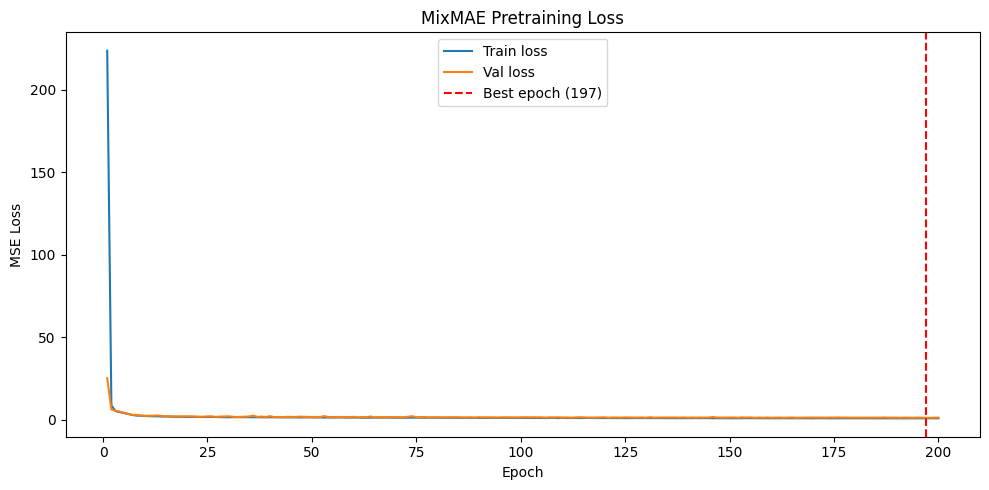

Loss curve saved to mixmae_8_all_loss_curve.png


In [15]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, label="Train loss")
plt.plot(epochs_range, val_losses,   label="Val loss")
plt.axvline(x=best_epoch, color="red", linestyle="--", label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MixMAE Pretraining Loss")
plt.legend()
plt.tight_layout()
plt.savefig("mixmae_8_all_loss_curve.png", dpi=150)
plt.show()
print("Loss curve saved to mixmae_8_all_loss_curve.png")

In [34]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# ===========================================================================
# Load checkpoint
# ===========================================================================

checkpoint = torch.load("mixmae_8_all_best.pt", map_location=device)
model.load_state_dict(checkpoint["model"])
model.eval()
print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")

# ===========================================================================
# Helper to unpatchify (reverse of patchify)
# ===========================================================================

def unpatchify(x, patch_size, num_channels, img_size=64):
    """
    x: (N, patch_size*patch_size*C)
    returns: (C, img_size, img_size)
    """
    h = img_size // patch_size
    x = x.reshape(h, h, patch_size, patch_size, num_channels)
    x = x.permute(4, 0, 2, 1, 3)           # (C, h, p, h, p)
    x = x.reshape(num_channels, img_size, img_size)
    return x

# ===========================================================================
# Pick a few val patches and reconstruct
# ===========================================================================

NUM_EXAMPLES = 100

fig, axs = plt.subplots(NUM_EXAMPLES, 6, figsize=(18, NUM_EXAMPLES * 3))
col_titles = ["S2 RGB (input)", "S2 RGB (recon)", "S2 masked positions",
              "S1 VV (input)",  "S1 VV (recon)",  "S1 masked positions"]

for i in range(NUM_EXAMPLES):
    # Load a single patch
    s2, s1 = val_dataset[i+100]
    s2_in = s2.unsqueeze(0).to(device)   # (1, 4, 64, 64)
    s1_in = s1.unsqueeze(0).to(device)   # (1, 2, 64, 64)

    with torch.no_grad():
        s2_pred, s1_pred, s2_mask, s1_mask = model(s2_in, s1_in)
        # s2_pred: (1, N, patch²×4)
        # s2_mask: (1, N) bool — True where S2 was masked

    # Unpatchify predictions — shape (N, D) → (C, H, W)
    s2_recon = unpatchify(s2_pred[0].cpu(), PATCH_SIZE_MODEL, 4)  # (4, 64, 64)
    s1_recon = unpatchify(s1_pred[0].cpu(), PATCH_SIZE_MODEL, 2)  # (2, 64, 64)

    # Build a visualisation of which patches were masked
    # Expand mask from (N,) to (H, W) by repeating per patch
    h = 64 // PATCH_SIZE_MODEL   # = 4
    s2_mask_img = s2_mask[0].cpu().reshape(h, h).float()
    s2_mask_img = s2_mask_img.repeat_interleave(PATCH_SIZE_MODEL, dim=0) \
                              .repeat_interleave(PATCH_SIZE_MODEL, dim=1)  # (64,64)

    s1_mask_img = s1_mask[0].cpu().reshape(h, h).float()
    s1_mask_img = s1_mask_img.repeat_interleave(PATCH_SIZE_MODEL, dim=0) \
                              .repeat_interleave(PATCH_SIZE_MODEL, dim=1)

    def norm(arr):
        arr = arr - arr.min()
        arr = arr / (arr.max() + 1e-6)
        return arr

    # S2 RGB: bands 0,1,2  (B4, B3, B2)
    s2_rgb_in    = norm(s2.numpy()[:3].transpose(1, 2, 0))
    s2_rgb_recon = norm(s2_recon.numpy()[:3].transpose(1, 2, 0))

    # S1 VV: band 0
    s1_vv_in    = s1.numpy()[0]
    s1_vv_recon = s1_recon.numpy()[0]

    axs[i, 0].imshow(s2_rgb_in)
    axs[i, 1].imshow(s2_rgb_recon)
    axs[i, 2].imshow(s2_mask_img, cmap="Reds", vmin=0, vmax=1)

    axs[i, 3].imshow(s1_vv_in,    cmap="gray")
    axs[i, 4].imshow(s1_vv_recon, cmap="gray")
    axs[i, 5].imshow(s1_mask_img, cmap="Reds", vmin=0, vmax=1)

    for j in range(6):
        axs[i, j].axis("off")

# Column titles on first row only
for j, title in enumerate(col_titles):
    axs[0, j].set_title(title, fontsize=10)

plt.suptitle("MixMAE Reconstruction — Val Patches", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("mixmae_reconstruction.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to mixmae_reconstruction.png")

Loaded checkpoint from epoch 197


Saved to mixmae_reconstruction.png


## Test

In [16]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from tqdm import tqdm

PATCH_SIZE = 8
IMG_SIZE = 64

def norm(arr):
    """Normalise numpy array to [0, 1]."""
    arr = arr - arr.min()
    return arr / (arr.max() + 1e-6)

def unpatchify(x, patch_size, num_channels, img_size=64):
    """
    x   : (N, patch_size * patch_size * num_channels)  — no batch dim
    out : (num_channels, img_size, img_size)
    """
    h = img_size // patch_size
    x = x.reshape(h, h, patch_size, patch_size, num_channels)
    x = x.permute(4, 0, 2, 1, 3)
    x = x.reshape(num_channels, img_size, img_size)
    return x

def mask_to_pixel(mask_1d, patch_size, img_size=64):
    """
    mask_1d : (N,) bool or float tensor
    Returns : (img_size, img_size) float numpy array  [0 or 1 per patch block]
    """
    h = img_size // patch_size
    m = mask_1d.float().reshape(h, h)
    m = m.repeat_interleave(patch_size, dim=0) \
         .repeat_interleave(patch_size, dim=1)
    return m.numpy()

def masked_composite(original_chw, recon_chw, mask_px):
    """
    original_chw, recon_chw : numpy (C, H, W)
    mask_px                 : numpy (H, W) float  [1 = masked position]
    Returns                 : numpy (H, W, 3) normalised RGB composite
    """
    composite = original_chw.copy()
    for c in range(composite.shape[0]):
        composite[c] = np.where(mask_px, recon_chw[c], original_chw[c])
    return norm(composite[:3].transpose(1, 2, 0))

print("Utilities loaded.")

Utilities loaded.


In [17]:
checkpoint = torch.load("mixmae_8_best.pt", map_location=device)
model.load_state_dict(checkpoint["model"])
model.eval()
print(f"Loaded checkpoint")
print(f"  Epoch    : {checkpoint['epoch']}")
print(f"  Val loss : {checkpoint['val_loss']:.6f}")
print(f"  Train loss: {checkpoint['train_loss']:.6f}")

Loaded checkpoint
  Epoch    : 124
  Val loss : 1.388806
  Train loss: 1.405392


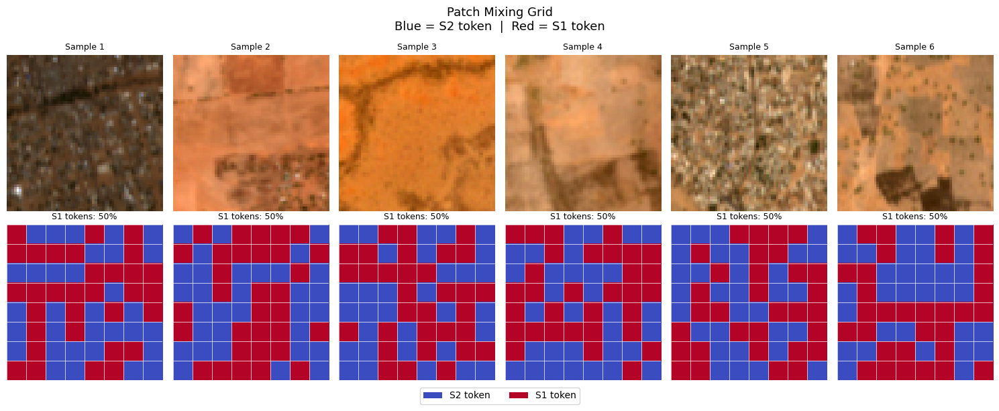

Saved → vis_1_mixing_grid.png

Mixing sanity check (all should be ~50%):
  Sample 1: 50.0% S1 tokens
  Sample 2: 50.0% S1 tokens
  Sample 3: 50.0% S1 tokens
  Sample 4: 50.0% S1 tokens
  Sample 5: 50.0% S1 tokens
  Sample 6: 50.0% S1 tokens


In [18]:
N_MIX_EXAMPLES = 6

fig, axs = plt.subplots(2, N_MIX_EXAMPLES, figsize=(N_MIX_EXAMPLES * 2.5, 6))
fig.suptitle("Patch Mixing Grid\nBlue = S2 token  |  Red = S1 token",
             fontsize=13)

for i in range(N_MIX_EXAMPLES):
    s2, s1 = val_dataset[i]
    s2_in  = s2.unsqueeze(0).to(device)
    s1_in  = s1.unsqueeze(0).to(device)

    with torch.no_grad():
        s2_tokens, s1_tokens = model.patch_embed(s2_in, s1_in)
        pe        = model._get_pos_embed(s2_tokens.shape[1], s2_tokens.device)
        s2_tokens = s2_tokens + pe
        s1_tokens = s1_tokens + pe
        _, s2_mask, s1_mask = mix_embeddings(s2_tokens, s1_tokens)

    mix_map = mask_to_pixel(s2_mask[0].cpu(), PATCH_SIZE, IMG_SIZE)
    # mix_map = 0 where S2 token present, 1 where S1 token present

    # Top row: S2 RGB input
    rgb = norm(s2.numpy()[:3].transpose(1, 2, 0))
    axs[0, i].imshow(rgb)
    axs[0, i].set_title(f"Sample {i+1}", fontsize=9)
    axs[0, i].axis("off")

    # Bottom row: mixing map
    axs[1, i].imshow(mix_map, cmap="coolwarm", vmin=0, vmax=1,
                     interpolation="nearest")
    s1_pct = int(mix_map.mean() * 100)
    axs[1, i].set_title(f"S1 tokens: {s1_pct}%", fontsize=9)
    axs[1, i].axis("off")

    # Patch boundary grid lines
    for k in range(0, IMG_SIZE, PATCH_SIZE):
        axs[1, i].axhline(k - 0.5, color="white", lw=0.5)
        axs[1, i].axvline(k - 0.5, color="white", lw=0.5)

axs[0, 0].set_ylabel("S2 RGB input", fontsize=9)
axs[1, 0].set_ylabel("Token source",  fontsize=9)

legend = [Patch(facecolor="#3b4cc0", label="S2 token"),
          Patch(facecolor="#b40426", label="S1 token")]
fig.legend(handles=legend, loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, -0.02), fontsize=10)

plt.tight_layout()
plt.savefig("vis_1_mixing_grid.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → vis_1_mixing_grid.png")

# Sanity check printout
print("\nMixing sanity check (all should be ~50%):")
for i in range(N_MIX_EXAMPLES):
    s2, s1 = val_dataset[i]
    with torch.no_grad():
        s2_t, s1_t = model.patch_embed(s2.unsqueeze(0).to(device),
                                        s1.unsqueeze(0).to(device))
        pe   = model._get_pos_embed(s2_t.shape[1], s2_t.device)
        s2_t += pe; s1_t += pe
        _, s2_mask, _ = mix_embeddings(s2_t, s1_t)
    pct = s2_mask[0].float().mean().item() * 100
    print(f"  Sample {i+1}: {pct:.1f}% S1 tokens")


In [32]:
# def norm_like(pred_arr, ref_arr):
#     """Normalise pred using the same scale as the reference (input) image."""
#     vmin = np.percentile(ref_arr, 2)
#     vmax = np.percentile(ref_arr, 98)
#     pred_arr = np.clip(pred_arr, vmin, vmax)
#     return (pred_arr - vmin) / (vmax - vmin + 1e-6)

def norm_like_rgb(pred_chw, ref_chw):
    """
    Normalise predicted RGB using a GLOBAL scale from the reference input.
    pred_chw : numpy (C, H, W) — predictions
    ref_chw  : numpy (C, H, W) — reference input (ground truth)
    Returns  : numpy (H, W, 3) correctly scaled RGB
    """
    # Use global min/max across ALL bands of the reference
    # so relative band ratios (which determine colour) are preserved
    vmin = np.percentile(ref_chw[:3], 2)
    vmax = np.percentile(ref_chw[:3], 98)

    rgb = pred_chw[:3].transpose(1, 2, 0).copy()
    rgb = np.clip(rgb, vmin, vmax)
    rgb = (rgb - vmin) / (vmax - vmin + 1e-6)
    return rgb

def norm_rgb_input(ref_chw):
    """Same scale for the input image itself."""
    vmin = np.percentile(ref_chw[:3], 2)
    vmax = np.percentile(ref_chw[:3], 98)
    rgb  = ref_chw[:3].transpose(1, 2, 0).copy()
    rgb  = np.clip(rgb, vmin, vmax)
    return (rgb - vmin) / (vmax - vmin + 1e-6)

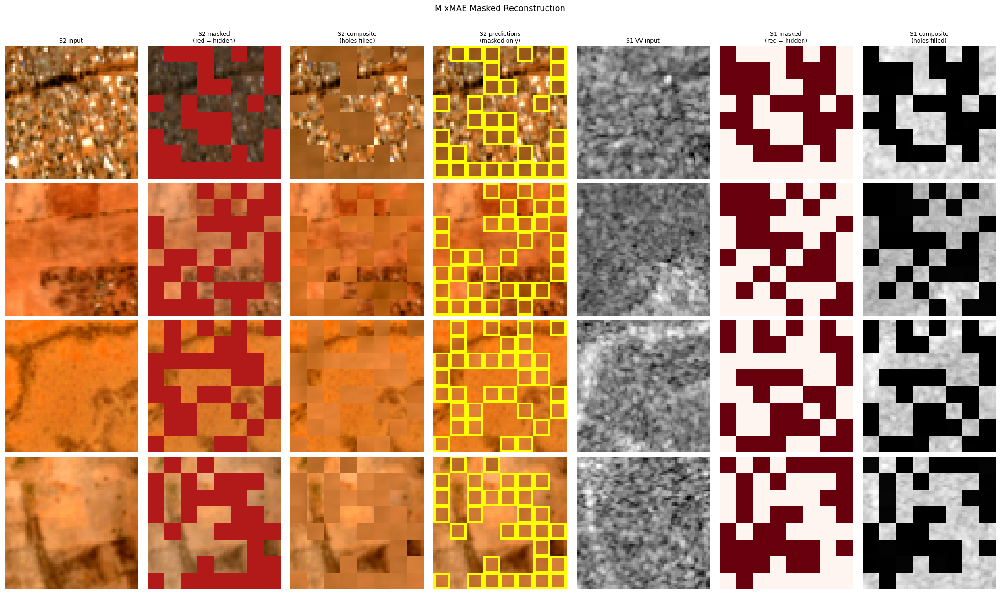

Saved → vis_2_reconstruction.png


In [33]:
N_RECON_EXAMPLES = 4

fig, axs = plt.subplots(N_RECON_EXAMPLES, 7,
                         figsize=(22, N_RECON_EXAMPLES * 3.2))

col_titles = [
    "S2 input",
    "S2 masked\n(red = hidden)",
    "S2 composite\n(holes filled)",
    "S2 predictions\n(masked only)",
    "S1 VV input",
    "S1 masked\n(red = hidden)",
    "S1 composite\n(holes filled)",
]

for i in range(N_RECON_EXAMPLES):
    s2, s1 = val_dataset[i]
    s2_in  = s2.unsqueeze(0).to(device)
    s1_in  = s1.unsqueeze(0).to(device)

    with torch.no_grad():
        s2_pred, s1_pred, s2_mask, s1_mask = model(s2_in, s1_in)

    # Unpatchify to pixel space
    s2_recon = unpatchify(s2_pred[0].cpu(), PATCH_SIZE, 4, IMG_SIZE)  # (4,64,64)
    s1_recon = unpatchify(s1_pred[0].cpu(), PATCH_SIZE, 2, IMG_SIZE)  # (2,64,64)

    # Pixel-space masks
    s2_mask_px = mask_to_pixel(s2_mask[0].cpu(), PATCH_SIZE, IMG_SIZE)
    s1_mask_px = mask_to_pixel(s1_mask[0].cpu(), PATCH_SIZE, IMG_SIZE)

    # S2 images
    s2_rgb_in = norm(s2.numpy()[:3].transpose(1, 2, 0))

    s2_masked_view = s2_rgb_in.copy()
    s2_masked_view[s2_mask_px.astype(bool)] = [0.7, 0.1, 0.1]   # red blocks

    # s2_composite = masked_composite(s2.numpy(), s2_recon.numpy(), s2_mask_px)

    # s2_pred_only = np.zeros_like(s2.numpy()[:3])
    # for c in range(3):
    #     s2_pred_only[c] = np.where(s2_mask_px, s2_recon.numpy()[c], 0)
    # s2_pred_only_rgb = norm(s2_pred_only.transpose(1, 2, 0))

    s2_recon_normed = np.stack([
        norm_like(s2_recon.numpy()[c], s2.numpy()[c]) for c in range(4)
    ])
    s2_composite = masked_composite(s2.numpy(), s2_recon_normed, s2_mask_px)
    
    s2_pred_only = np.zeros_like(s2.numpy()[:3])
    for c in range(3):
        s2_pred_only[c] = np.where(s2_mask_px, s2_recon_normed[c], 0)
    s2_pred_only_rgb = s2_pred_only.transpose(1, 2, 0)

    # S1 images
    s1_vv_in = s1.numpy()[0]
    s1_recon_normed = norm_like(s1_recon.numpy()[0], s1.numpy()[0])
    s1_comp_vv = np.where(s1_mask_px, s1_recon_normed, s1_vv_in)

    # Plot
    axs[i, 0].imshow(s2_rgb_in)
    axs[i, 1].imshow(s2_masked_view)
    axs[i, 2].imshow(s2_composite)
    axs[i, 3].imshow(s2_pred_only_rgb)
    axs[i, 4].imshow(s1_vv_in,    cmap="gray")
    axs[i, 5].imshow(s1_mask_px,  cmap="Reds",  vmin=0, vmax=1)
    axs[i, 6].imshow(s1_comp_vv,  cmap="gray")

    n2 = int(s2_mask[0].sum().item())
    n1 = int(s1_mask[0].sum().item())
    axs[i, 1].set_xlabel(f"{n2} patches masked", fontsize=8)
    axs[i, 5].set_xlabel(f"{n1} patches masked", fontsize=8)

    s2_rgb_in = norm_rgb_input(s2.numpy())
    s2_recon_rgb = norm_like_rgb(s2_recon.numpy(), s2.numpy())
    
    # Composite: input where visible, prediction where masked
    s2_composite = s2_rgb_in.copy()
    for c in range(3):
        s2_composite[:, :, c] = np.where(
            s2_mask_px.astype(bool),
            s2_recon_rgb[:, :, c],
            s2_rgb_in[:, :, c]
        )
    
    # Overlay: full image with yellow borders on predicted patches
    s2_pred_overlay = s2_rgb_in.copy()
    for c in range(3):
        s2_pred_overlay[:, :, c] = np.where(
            s2_mask_px.astype(bool),
            s2_recon_rgb[:, :, c],
            s2_rgb_in[:, :, c]
        )
    border = np.zeros_like(s2_mask_px)
    h_grid = IMG_SIZE // PATCH_SIZE
    for r in range(h_grid):
        for c_idx in range(h_grid):
            if s2_mask[0][r * h_grid + c_idx]:
                r0, r1 = r*PATCH_SIZE, (r+1)*PATCH_SIZE
                c0, c1 = c_idx*PATCH_SIZE, (c_idx+1)*PATCH_SIZE
                border[r0, c0:c1] = 1;   border[r1-1, c0:c1] = 1
                border[r0:r1, c0] = 1;   border[r0:r1, c1-1] = 1
    s2_pred_overlay[border.astype(bool)] = [1.0, 1.0, 0.0]
    
    # Plot — same as before
    axs[i, 0].imshow(s2_rgb_in)
    axs[i, 1].imshow(s2_masked_view)
    axs[i, 2].imshow(s2_composite)
    axs[i, 3].imshow(s2_pred_overlay)

    for j in range(7):
        axs[i, j].axis("off")

for j, title in enumerate(col_titles):
    axs[0, j].set_title(title, fontsize=9)

plt.suptitle("MixMAE Masked Reconstruction", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("vis_2_reconstruction.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → vis_2_reconstruction.png")

In [31]:
model.eval()
with torch.no_grad():
    s2, s1 = val_dataset[2]   # row 3
    s2_pred, s1_pred, s2_mask, s1_mask = model(
        s2.unsqueeze(0).to(device),
        s1.unsqueeze(0).to(device)
    )

s2_recon = unpatchify(s2_pred[0].cpu(), PATCH_SIZE, 4, IMG_SIZE).numpy()

print("Input ranges:")
for i, name in enumerate(["B4(R)", "B3(G)", "B2(B)", "NIR"]):
    print(f"  {name}: [{s2.numpy()[i].min():.4f}, {s2.numpy()[i].max():.4f}]")

print("\\nPrediction ranges:")
for i, name in enumerate(["B4(R)", "B3(G)", "B2(B)", "NIR"]):
    print(f"  {name}: [{s2_recon[i].min():.4f}, {s2_recon[i].max():.4f}]")

print("\\nAfter norm_like:")
for i, name in enumerate(["B4(R)", "B3(G)", "B2(B)"]):
    normed = norm_like(s2_recon[i], s2.numpy()[i])
    print(f"  {name}: [{normed.min():.4f}, {normed.max():.4f}]  mean={normed.mean():.4f}")

Input ranges:
  B4(R): [0.3366, 0.4837]
  B3(G): [0.2448, 0.3410]
  B2(B): [0.1620, 0.2371]
  NIR: [0.4254, 0.5496]
\nPrediction ranges:
  B4(R): [0.0774, 0.4492]
  B3(G): [0.0709, 0.3367]
  B2(B): [0.0473, 0.2502]
  NIR: [0.2367, 0.6895]
\nAfter norm_like:
  B4(R): [0.0000, 0.8142]  mean=0.2978
  B3(G): [0.0000, 1.0000]  mean=0.4328
  B2(B): [0.0000, 1.0000]  mean=0.5062


Sample 1:
  S2 input  range: [0.1068, 0.9200]
  S2 pred   range: [0.0613, 0.4488]
  S1 input  range: [14.9136, 24.6538]
  S1 pred   range: [8.1441, 20.2285]
Sample 2:
  S2 input  range: [0.1572, 0.4662]
  S2 pred   range: [0.0474, 0.4528]
  S1 input  range: [11.7609, 22.2272]
  S1 pred   range: [6.3393, 18.0332]
Sample 3:
  S2 input  range: [0.1620, 0.4837]
  S2 pred   range: [0.0516, 0.4529]
  S1 input  range: [12.0412, 21.9866]
  S1 pred   range: [7.1443, 19.1001]
Sample 4:
  S2 input  range: [0.1118, 0.5002]
  S2 pred   range: [0.0410, 0.4373]
  S1 input  range: [13.0103, 20.0000]
  S1 pred   range: [6.7836, 18.6843]


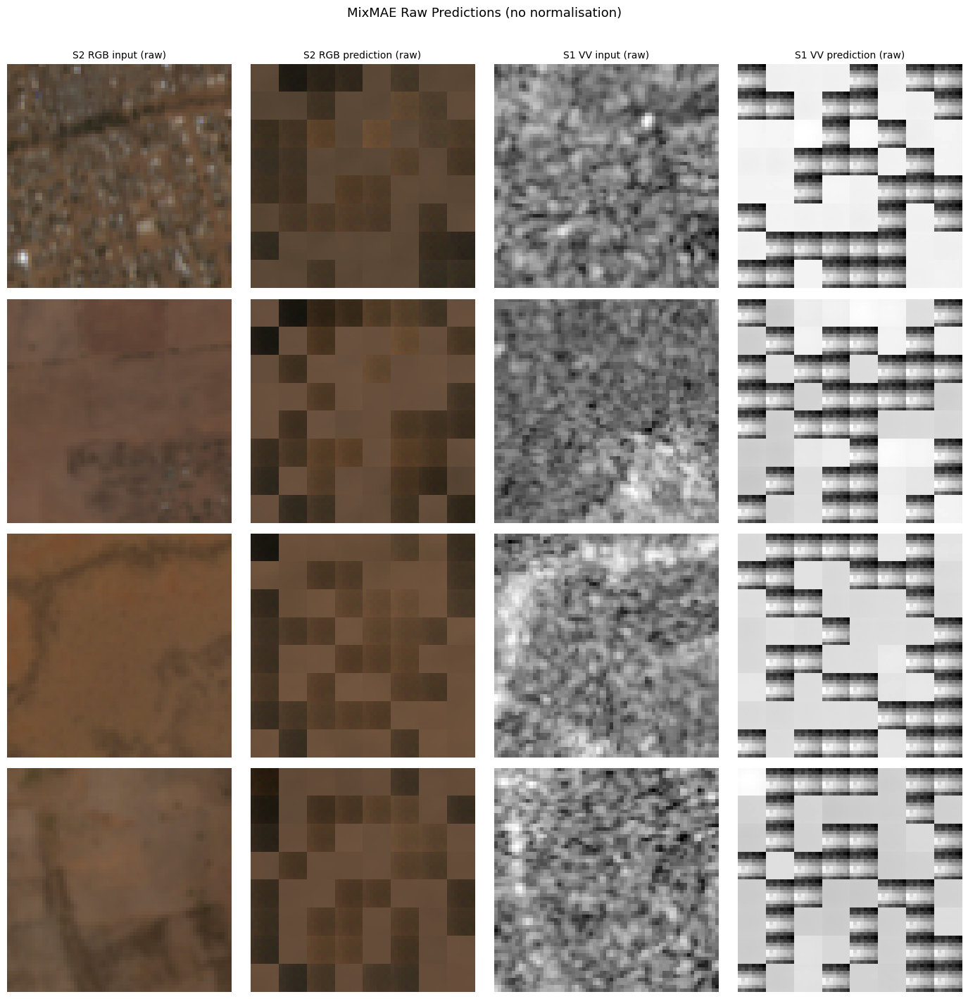

In [21]:
N_RAW_EXAMPLES = 4

fig, axs = plt.subplots(N_RAW_EXAMPLES, 4,
                         figsize=(14, N_RAW_EXAMPLES * 3.5))

col_titles = [
    "S2 RGB input (raw)",
    "S2 RGB prediction (raw)",
    "S1 VV input (raw)",
    "S1 VV prediction (raw)",
]

for i in range(N_RAW_EXAMPLES):
    s2, s1 = val_dataset[i]
    s2_in  = s2.unsqueeze(0).to(device)
    s1_in  = s1.unsqueeze(0).to(device)

    with torch.no_grad():
        s2_pred, s1_pred, s2_mask, s1_mask = model(s2_in, s1_in)

    s2_recon = unpatchify(s2_pred[0].cpu(), PATCH_SIZE, 4, IMG_SIZE).numpy()
    s1_recon = unpatchify(s1_pred[0].cpu(), PATCH_SIZE, 2, IMG_SIZE).numpy()

    # Raw input — just transpose to HWC, no scaling
    s2_raw_in    = s2.numpy()[:3].transpose(1, 2, 0)   # (64, 64, 3)
    s2_raw_pred  = s2_recon[:3].transpose(1, 2, 0)     # (64, 64, 3)

    s1_raw_in    = s1.numpy()[0]                        # (64, 64)
    s1_raw_pred  = s1_recon[0]                          # (64, 64)

    # Print value ranges so you can see what the model is outputting
    print(f"Sample {i+1}:")
    print(f"  S2 input  range: [{s2_raw_in.min():.4f}, {s2_raw_in.max():.4f}]")
    print(f"  S2 pred   range: [{s2_raw_pred.min():.4f}, {s2_raw_pred.max():.4f}]")
    print(f"  S1 input  range: [{s1_raw_in.min():.4f}, {s1_raw_in.max():.4f}]")
    print(f"  S1 pred   range: [{s1_raw_pred.min():.4f}, {s1_raw_pred.max():.4f}]")

    # Clip to valid reflectance range for S2 [0,1] and reasonable dB for S1
    # This is NOT normalisation — just preventing matplotlib from
    # clipping negative values to black
    s2_display_in   = np.clip(s2_raw_in,   0, 1)
    s2_display_pred = np.clip(s2_raw_pred, 0, 1)

    axs[i, 0].imshow(s2_display_in)
    axs[i, 1].imshow(s2_display_pred)
    axs[i, 2].imshow(s1_raw_in,   cmap="gray")
    axs[i, 3].imshow(s1_raw_pred, cmap="gray")

    # Annotate with actual value ranges
    axs[i, 1].set_xlabel(
        f"pred range: [{s2_raw_pred.min():.3f}, {s2_raw_pred.max():.3f}]",
        fontsize=7
    )
    axs[i, 3].set_xlabel(
        f"pred range: [{s1_raw_pred.min():.2f}, {s1_raw_pred.max():.2f}]",
        fontsize=7
    )

    for j in range(4):
        axs[i, j].axis("off")

for j, title in enumerate(col_titles):
    axs[0, j].set_title(title, fontsize=10)

plt.suptitle("MixMAE Raw Predictions (no normalisation)", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("vis_raw_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

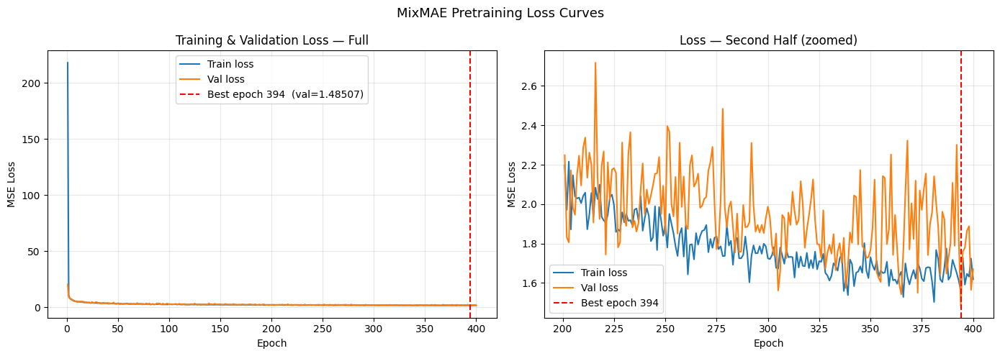

Saved → vis_3_loss_curves.png

Best epoch      : 394
Best val loss   : 1.485070
Final train loss: 1.618709
Final val loss  : 1.669782
Train/val gap   : 0.051072  (slight overfit)


In [22]:
train_losses = np.load("mixmae_train_losses.npy")
val_losses   = np.load("mixmae_val_losses.npy")
epochs       = np.arange(1, len(train_losses) + 1)
best_epoch   = int(np.argmin(val_losses)) + 1
best_val     = val_losses[best_epoch - 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full curve
axes[0].plot(epochs, train_losses, label="Train loss", linewidth=1.5)
axes[0].plot(epochs, val_losses,   label="Val loss",   linewidth=1.5)
axes[0].axvline(best_epoch, color="red", linestyle="--",
                label=f"Best epoch {best_epoch}  (val={best_val:.5f})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training & Validation Loss — Full")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Zoomed: second half of training
mid = len(epochs) // 2
axes[1].plot(epochs[mid:], train_losses[mid:], label="Train loss")
axes[1].plot(epochs[mid:], val_losses[mid:],   label="Val loss")
axes[1].axvline(best_epoch, color="red", linestyle="--",
                label=f"Best epoch {best_epoch}")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE Loss")
axes[1].set_title("Loss — Second Half (zoomed)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("MixMAE Pretraining Loss Curves", fontsize=13)
plt.tight_layout()
plt.savefig("vis_3_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → vis_3_loss_curves.png")

print(f"\nBest epoch      : {best_epoch}")
print(f"Best val loss   : {best_val:.6f}")
print(f"Final train loss: {train_losses[-1]:.6f}")
print(f"Final val loss  : {val_losses[-1]:.6f}")
gap = float(val_losses[-1]) - float(train_losses[-1])
print(f"Train/val gap   : {gap:.6f}  "
      f"({'slight overfit' if gap > 0.001 else 'healthy'})")


In [23]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import rasterio

# --- Step 1: Extract features ---
print("Step 1/4: Extracting encoder features...")
model.eval()
all_features = []

with torch.no_grad():
    for s2, s1 in tqdm(val_loader, desc="Extracting"):
        s2 = s2.to(device)
        s1 = s1.to(device)

        s2_tokens, s1_tokens = model.patch_embed(s2, s1)
        pe        = model._get_pos_embed(s2_tokens.shape[1], s2_tokens.device)
        s2_tokens = s2_tokens + pe

        # S2-only encoding — mirrors downstream inference
        encoded = model.encoder(s2_tokens)       # (B, N, D)
        pooled  = encoded.mean(dim=1)            # (B, D) global avg pool
        all_features.append(pooled.cpu())

features = torch.cat(all_features, dim=0).numpy()
print(f"Features shape: {features.shape}")

# --- Step 2: Urban ratios for colouring ---
print("Step 2/4: Computing urban ratios...")
urban_ratios = []
with rasterio.open(LULC_2019_PATH) as lulc_ds:
    for fpath in tqdm(val_paths, desc="LULC"):
        fname = os.path.basename(fpath)
        parts = fname.replace(".npz", "").split("_")
        row   = int(parts[1][1:])
        col   = int(parts[2][1:])
        win   = rasterio.windows.Window(col, row, IMG_SIZE, IMG_SIZE)
        try:
            patch = lulc_ds.read(1, window=win)
            urban_ratios.append(np.mean(patch == URBAN_CLASS))
        except Exception:
            urban_ratios.append(0.0)
urban_ratios = np.array(urban_ratios)
print(f"Urban ratio range: {urban_ratios.min():.2f} – {urban_ratios.max():.2f}")

# --- Step 3: PCA ---
print("Step 3/4: Running PCA (50 components)...")
n_components = min(50, features.shape[1], features.shape[0])
pca = PCA(n_components=n_components)
pca_feats= pca.fit_transform(features)
explained = pca.explained_variance_ratio_.cumsum()
n90 = int(np.searchsorted(explained, 0.90)) + 1
print(f"PCA: {explained[-1]*100:.1f}% variance in {n_components} components")
print(f"{n90} components needed for 90% variance")

# --- Step 4: t-SNE ---
print("Step 4/4: Running t-SNE (may take a minute)...")
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42, verbose=0)
proj = tsne.fit_transform(pca_feats)
print("t-SNE complete.")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# t-SNE scatter coloured by urban ratio
sc = axes[0].scatter(proj[:, 0], proj[:, 1], c=urban_ratios, cmap="RdYlGn_r", s=4, alpha=0.6)
plt.colorbar(sc, ax=axes[0], label="Urban ratio")

top_urban = np.where(urban_ratios > 0.8)[0]
low_urban = np.where(urban_ratios < 0.1)[0]
if len(top_urban):
    axes[0].scatter(proj[top_urban, 0], proj[top_urban, 1],
                    c="red", s=10, alpha=0.9, label=f"High urban >80% (n={len(top_urban)})")
if len(low_urban):
    axes[0].scatter(proj[low_urban, 0], proj[low_urban, 1],
                    c="green", s=10, alpha=0.9, label=f"Low urban <10% (n={len(low_urban)})")

axes[0].set_title("t-SNE of Encoder Embeddings\n(coloured by urban ratio)")
axes[0].set_xlabel("t-SNE dim 1")
axes[0].set_ylabel("t-SNE dim 2")
axes[0].legend(fontsize=8, markerscale=2)
axes[0].grid(alpha=0.2)

# PCA variance explained
axes[1].plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
             explained * 100, linewidth=1.5)
axes[1].axhline(90, color="red", linestyle="--", label="90% threshold")
axes[1].axvline(n90, color="red", linestyle=":", alpha=0.6)
axes[1].annotate(f"{n90} components\nfor 90%",
                 xy=(n90, 90), xytext=(n90 + 2, 75),
                 arrowprops=dict(arrowstyle="->", color="red"),
                 fontsize=9, color="red")
axes[1].set_xlabel("Number of PCA components")
axes[1].set_ylabel("Cumulative variance explained (%)")
axes[1].set_title("PCA Variance Explained\n(proxy for representation richness)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("MixMAE Latent Space Analysis", fontsize=13)
plt.tight_layout()
plt.savefig("vis_4_latent_space.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved to vis_4_latent_space.png")

Step 1/4: Extracting encoder features...


Features shape: (20040, 256)
Step 2/4: Computing urban ratios...


Urban ratio range: 0.00 – 1.00
Step 3/4: Running PCA (50 components)...
PCA: 100.0% variance in 50 components
2 components needed for 90% variance
Step 4/4: Running t-SNE (may take a minute)...


In [24]:
model.eval()
pred_means = []

with torch.no_grad():
    for i in range(10):
        s2, s1 = val_dataset[i]
        s2_pred, s1_pred, s2_mask, s1_mask = model(
            s2.unsqueeze(0).to(device),
            s1.unsqueeze(0).to(device)
        )
        pred_means.append(s2_pred[0].mean().item())

print("S2 prediction means across 10 patches:")
for i, m in enumerate(pred_means):
    print(f"  Patch {i+1}: {m:.6f}")

variation = np.std(pred_means)
print(f"\\nStd of means: {variation:.6f}")
print(f"{'Good — predictions vary per patch' if variation > 0.01 else 'BAD — predictions nearly identical across patches'}")

S2 prediction means across 10 patches:
  Patch 1: 0.292138
  Patch 2: 0.319701
  Patch 3: 0.326154
  Patch 4: 0.328689
  Patch 5: 0.300095
  Patch 6: 0.296011
  Patch 7: 0.284720
  Patch 8: 0.316958
  Patch 9: 0.302097
  Patch 10: 0.309715
\nStd of means: 0.014181
Good — predictions vary per patch


In [25]:
model.eval()

with torch.no_grad():
    s2, s1 = val_dataset[0]
    s2_in  = s2.unsqueeze(0).to(device)
    s1_in  = s1.unsqueeze(0).to(device)

    s2_pred, s1_pred, s2_mask, s1_mask = model(s2_in, s1_in)

    # Patchify ground truth
    s2_patches_gt = patchify(s2_in, PATCH_SIZE)   # (1, N, patch²×4)

    # Compare masked tokens only
    masked_idx  = s2_mask[0].bool()
    gt_masked   = s2_patches_gt[0][masked_idx]     # (n_masked, patch²×4)
    pred_masked = s2_pred[0][masked_idx]

    # Per-token MSE
    token_mse = ((gt_masked - pred_masked) ** 2).mean(dim=1)  # (n_masked,)

    print(f"Masked tokens : {masked_idx.sum().item()}")
    print(f"Token MSE mean: {token_mse.mean().item():.6f}")
    print(f"Token MSE std : {token_mse.std().item():.6f}")
    print(f"Token MSE min : {token_mse.min().item():.6f}")
    print(f"Token MSE max : {token_mse.max().item():.6f}")

    # Mean colour of GT vs prediction per token
    gt_mean   = gt_masked.mean(dim=1)    # (n_masked,)
    pred_mean = pred_masked.mean(dim=1)

    print(f"\\nGT token means   : {gt_mean[:5].cpu().numpy().round(4)}")
    print(f"Pred token means : {pred_mean[:5].cpu().numpy().round(4)}")

Masked tokens : 32
Token MSE mean: 0.002120
Token MSE std : 0.001061
Token MSE min : 0.000681
Token MSE max : 0.005098
\nGT token means   : [0.3313 0.3323 0.3613 0.3289 0.3203]
Pred token means : [0.3338 0.3342 0.3269 0.3309 0.3361]


In [26]:
model.eval()

with torch.no_grad():
    s2, s1 = val_dataset[0]
    s2_in  = s2.unsqueeze(0).to(device)
    s1_in  = s1.unsqueeze(0).to(device)

    # Run twice — predictions should be DIFFERENT each time
    # because masking is random
    s2_pred_a, _, s2_mask_a, _ = model(s2_in, s1_in)
    s2_pred_b, _, s2_mask_b, _ = model(s2_in, s1_in)

    masks_differ = (s2_mask_a != s2_mask_b).any().item()
    preds_differ = (s2_pred_a - s2_pred_b).abs().mean().item()

    print(f"Masks differ between runs : {masks_differ}")
    print(f"Pred diff between runs    : {preds_differ:.6f}")
    print(f"{'Good — random masking working' if masks_differ else 'BAD — mask is not random'}")

Masks differ between runs : True
Pred diff between runs    : 0.048528
Good — random masking working


In [27]:
model.eval()
with torch.no_grad():
    s2, s1 = val_dataset[2]   # the blue one — row 3
    s2_pred, s1_pred, s2_mask, s1_mask = model(
        s2.unsqueeze(0).to(device),
        s1.unsqueeze(0).to(device)
    )

s2_recon = unpatchify(s2_pred[0].cpu(), PATCH_SIZE, 4, IMG_SIZE).numpy()

print("Per-band prediction ranges:")
bands = ["B4 (red)", "B3 (green)", "B2 (blue)", "NIR"]
for i, name in enumerate(bands):
    print(f"  {name}: [{s2_recon[i].min():.4f}, {s2_recon[i].max():.4f}]  mean={s2_recon[i].mean():.4f}")

print(f"\\nS2 input ranges:")
for i, name in enumerate(bands):
    print(f"  {name}: [{s2.numpy()[i].min():.4f}, {s2.numpy()[i].max():.4f}]  mean={s2.numpy()[i].mean():.4f}")

Per-band prediction ranges:
  B4 (red): [0.0808, 0.4512]  mean=0.3596
  B3 (green): [0.0736, 0.3362]  mean=0.2697
  B2 (blue): [0.0483, 0.2476]  mean=0.1918
  NIR: [0.2420, 0.6849]  mean=0.5101
\nS2 input ranges:
  B4 (red): [0.3366, 0.4837]  mean=0.4288
  B3 (green): [0.2448, 0.3410]  mean=0.3082
  B2 (blue): [0.1620, 0.2371]  mean=0.2081
  NIR: [0.4254, 0.5496]  mean=0.5070


# Another AuxMAE Implementation (With S1 being auxiliary)

In [2]:
import os
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from einops import repeat
from tqdm import tqdm
import matplotlib.pyplot as plt
import glob
import psutil
import timm
from timm.models.vision_transformer import Block
 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [18]:
IMG_SIZE = 64
PATCH_SIZE = 4
IN_CHANNELS_S2 = 4
IN_CHANNELS_S1 = 1
EMBED_DIM = 256
ENCODER_DEPTH = 6
ENCODER_HEADS = 8
DECODER_EMBED_DIM = 128
DECODER_DEPTH = 4
DECODER_HEADS = 8
AUX_DECODER_DEPTH = 2
MASK_RATIO = 0.75
AUX_LOSS_WEIGHT = 0.5
BATCH_SIZE = 128
NUM_EPOCHS = 10
LR = 1.5e-4
WARMUP_EPOCHS = 40
MAE_PATCH_DIR = "data/mae_patches_all"
CHECKPOINT_PATH = "auxmae_shared_best_4.pt"
 
NUM_PATCHES = (IMG_SIZE // PATCH_SIZE) ** 2
PATCH_DIM_S2 = PATCH_SIZE * PATCH_SIZE * IN_CHANNELS_S2
PATCH_DIM_S1 = PATCH_SIZE * PATCH_SIZE * IN_CHANNELS_S1
 
print(f"Patches per image: {NUM_PATCHES}")
print(f"S2 patch dim: {PATCH_DIM_S2}")
print(f"S1 patch dim: {PATCH_DIM_S1}")
print(f"Masked per image: {int(NUM_PATCHES * MASK_RATIO)}")

Patches per image: 256
S2 patch dim: 64
S1 patch dim: 16
Masked per image: 192


In [19]:
class AuxMAE(nn.Module):
    def __init__(
        self,
        img_size=IMG_SIZE,
        patch_size=PATCH_SIZE,
        in_ch_s2=IN_CHANNELS_S2,
        in_ch_s1=IN_CHANNELS_S1,
        embed_dim=EMBED_DIM,
        encoder_depth=ENCODER_DEPTH,
        encoder_heads=ENCODER_HEADS,
        decoder_embed_dim=DECODER_EMBED_DIM,
        decoder_depth=DECODER_DEPTH,
        decoder_heads=DECODER_HEADS,
        aux_decoder_depth=AUX_DECODER_DEPTH,
        mask_ratio=MASK_RATIO,
        aux_loss_weight=AUX_LOSS_WEIGHT,
    ):
        super().__init__()
        self.patch_size = patch_size
        self.mask_ratio = mask_ratio
        self.embed_dim = embed_dim
 
        num_patches = (img_size // patch_size) ** 2
        patch_dim_s2 = patch_size * patch_size * in_ch_s2
        patch_dim_s1 = patch_size * patch_size * in_ch_s1
 
        # S2 patch embedding
        self.s2_patch_embed = nn.Sequential(
            nn.LayerNorm(patch_dim_s2),
            nn.Linear(patch_dim_s2, embed_dim),
            nn.LayerNorm(embed_dim),
        )
 
        # Shared positional embeddings 
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches, embed_dim))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
 
        # Shared ViT encoder
        self.encoder_blocks = nn.ModuleList([
            Block(
                dim=embed_dim,
                num_heads=encoder_heads,
                mlp_ratio=4.0,
                qkv_bias=True,
                norm_layer=nn.LayerNorm,
            )
            for _ in range(encoder_depth)
        ])
        self.encoder_norm = nn.LayerNorm(embed_dim)
 
        # Mask token for masked S2 positions
        self.mask_token = nn.Parameter(torch.zeros(1, 1, decoder_embed_dim))
        nn.init.trunc_normal_(self.mask_token, std=0.02)
 
        # Project encoder_dim to decoder_dim
        self.enc_to_dec = nn.Linear(embed_dim, decoder_embed_dim)
 
        # Decoder positional embeddings
        self.decoder_pos_embed = nn.Parameter(
            torch.zeros(1, num_patches, decoder_embed_dim)
        )
        nn.init.trunc_normal_(self.decoder_pos_embed, std=0.02)
 
        # Task 1 decoder (reconstructs masked S2 patches)
        self.s2_decoder_blocks = nn.ModuleList([
            Block(
                dim=decoder_embed_dim,
                num_heads=decoder_heads,
                mlp_ratio=4.0,
                qkv_bias=True,
                norm_layer=nn.LayerNorm
                )
            for _ in range(decoder_depth)
        ])
        self.s2_decoder_norm = nn.LayerNorm(decoder_embed_dim)
        self.s2_decoder_pred = nn.Linear(decoder_embed_dim, patch_dim_s2)
 
        # Task 2 aux decoder (S1 prediction from S2 input)
        self.s1_decoder_blocks = nn.ModuleList([
            Block(
                dim=decoder_embed_dim,
                num_heads=decoder_heads,
                mlp_ratio=4.0,
                qkv_bias=True,
                norm_layer=nn.LayerNorm
                )
            for _ in range(aux_decoder_depth)
        ])
        self.s1_decoder_norm = nn.LayerNorm(decoder_embed_dim)
        self.s1_decoder_pred = nn.Linear(decoder_embed_dim, patch_dim_s1)
 
        self._init_weights()
 
    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def _normalise_patches(self, patches):
        mean = patches.mean(dim=-1, keepdim=True)
        std = patches.std(dim=-1, keepdim=True) + 1e-6
        return (patches - mean) / std

    def _image_to_patches(self, img):
        B, C, H, W = img.shape
        p = self.patch_size
        h = H // p

        x = img.reshape(B, C, h, p, h, p)
        x = x.permute(0, 2, 4, 3, 5, 1)
        return x.reshape(B, h * h, p * p * C)
 
    def _run_encoder(self, tokens):
        for blk in self.encoder_blocks:
            tokens = blk(tokens)
        return self.encoder_norm(tokens)
 
    def random_masking(self, x):
        B, N, D = x.shape
        len_keep = int(N * (1 - self.mask_ratio))
 
        noise = torch.rand(B, N, device=x.device)
        ids_shuffle = torch.argsort(noise, dim=1)
        ids_restore = torch.argsort(ids_shuffle, dim=1)
 
        ids_keep = ids_shuffle[:, :len_keep]
        x_visible = torch.gather(x, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
 
        mask = torch.ones(B, N, device=x.device)
        mask[:, :len_keep] = 0
        mask = torch.gather(mask, 1, ids_restore)
 
        return x_visible, mask, ids_restore
 
 
    def forward_decoder_s2(self, encoded, ids_restore):
        """
        Decode S2 - restore full sequence with mask tokens then reconstruct.
        """
        B = encoded.shape[0]
        N = ids_restore.shape[1]
 
        x = self.enc_to_dec(encoded)
 
        # Append mask tokens to fill in masked positions
        n_masked = N - x.shape[1]
        mask_tokens = self.mask_token.expand(B, n_masked, -1)
        x_ = torch.cat([x, mask_tokens], dim=1)
 
        # Restore original patch order
        x_ = torch.gather(x_, 1,ids_restore.unsqueeze(-1).expand(-1, -1, x_.shape[2]))
 
        # Add decoder positional embeddings
        x_ = x_ + self.decoder_pos_embed
 
        for blk in self.s2_decoder_blocks:
            x_ = blk(x_)
        x_ = self.s2_decoder_norm(x_)
        return self.s2_decoder_pred(x_)
 
    def forward_decoder_s1(self, encoded_full):
        """
        Decode S1 - predict all S1 patches from shared encoder output.
        """
        x = self.enc_to_dec(encoded_full)
        x = x + self.decoder_pos_embed
 
        for blk in self.s1_decoder_blocks:
            x = blk(x)
            
        x = self.s1_decoder_norm(x)
        return self.s1_decoder_pred(x)
 
    def forward(self, s2, s1=None, task="s2_reconstruction"):
        # S2 reconstruction
        if task == "s2_reconstruction":
            s2_patches = self._image_to_patches(s2)
            s2_normalised = self._normalise_patches(s2_patches)
            tokens = self.s2_patch_embed(s2_patches) + self.pos_embed
            x_visible, mask, ids_restore = self.random_masking(tokens)
            encoded = self._run_encoder(x_visible)
            pred_s2 = self.forward_decoder_s2(encoded, ids_restore)

             # Compute loss on masked patches
            mask_expanded = mask.unsqueeze(-1)
            loss = ((pred_s2 - s2_normalised) ** 2 * mask_expanded).sum() / (
                mask.sum() * s2_normalised.shape[-1]
            )

            return loss, pred_s2, mask

        # S1 reconstruction
        elif task == "s1_prediction":
            s2_patches = self._image_to_patches(s2)
            tokens = self.s2_patch_embed(s2_patches) + self.pos_embed
            encoded_full = self._run_encoder(tokens)
            pred_s1 = self.forward_decoder_s1(encoded_full)
            
            s1_patches = self._image_to_patches(s1)
            recon_loss = F.mse_loss(pred_s1, s1_patches)

            # Reshape to image space to compute boundary penalty
            B = s1.shape[0]
            h = IMG_SIZE // self.patch_size
            pred_img = pred_s1.reshape(B, h, h, self.patch_size, self.patch_size, IN_CHANNELS_S1)
            pred_img = pred_img.permute(0, 5, 1, 3, 2, 4).reshape(B, IN_CHANNELS_S1, IMG_SIZE, IMG_SIZE)
        
            # Penalise jumps at horizontal and vertical patch boundaries
            h_bounds = torch.arange(self.patch_size - 1, IMG_SIZE - 1, self.patch_size, device=s1.device)
            v_bounds = torch.arange(self.patch_size - 1, IMG_SIZE - 1, self.patch_size, device=s1.device)
            horiz = (pred_img[:, :, h_bounds, :] - pred_img[:, :, h_bounds + 1, :]) ** 2
            vert  = (pred_img[:, :, :, v_bounds] - pred_img[:, :, :, v_bounds + 1]) ** 2
            smooth_loss = horiz.mean() + vert.mean()
        
            loss = recon_loss + 0.05 * smooth_loss
            return loss, pred_s1, None
 
 
model = AuxMAE().to(device)
 
n_total = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {n_total/1e6:.2f}M")
 
model = AuxMAE().to(device)
s2_test = torch.randn(2, IN_CHANNELS_S2, IMG_SIZE, IMG_SIZE).to(device)
s1_test = torch.randn(2, IN_CHANNELS_S1, IMG_SIZE, IMG_SIZE).to(device)

# Test Task 1
loss1, _, _ = model(s2_test, s1_test, task="s2_reconstruction")
# Test Task 2
loss2, _, _ = model(s2_test, s1_test, task="s1_prediction")

print(f"Test Successful!")
print(f"Task 1 Loss (S2->S2): {loss1.item():.4f}")
print(f"Task 2 Loss (S2->S1): {loss2.item():.4f}")

Total params: 6.09M
Test Successful!
Task 1 Loss (S2->S2): 1.0365
Task 2 Loss (S2->S1): 1.0678


In [20]:
class AuxMAEDataset(Dataset):
    def __init__(self, patch_paths):
        self.paths = patch_paths
        # Values for the range of the s1 (so that we can normalise)
        self.s1_min = -60.0
        self.s1_max = 25.0
 
    def __len__(self):
        return len(self.paths)
 
    def __getitem__(self, idx):
        # Load from disk
        with np.load(self.paths[idx]) as f:
            img = f["image"].astype(np.float32)

        s2 = img[:4]
        s1 = img[4:]

        # Normalise S2 (simply clip to [0, 1])
        s2 = np.clip(s2, 0.0, 1.0)

        # Normalise S1 (scale -60.0 to 25.0 into the [0, 1] range)
        s1 = (s1 - self.s1_min) / (self.s1_max - self.s1_min)
        s1 = np.clip(s1, 0.0, 1.0)

        return torch.from_numpy(s2), torch.from_numpy(s1)

In [21]:
all_paths = sorted(glob.glob(os.path.join(MAE_PATCH_DIR, "*.npz")))
random.shuffle(all_paths)
split = int(len(all_paths) * 0.9)
train_paths = all_paths[:split]
val_paths_mae = all_paths[split:]
print(f"Train: {len(train_paths):,}  Val: {len(val_paths_mae):,}")
 
train_dataset = AuxMAEDataset(train_paths)
val_dataset_mae = AuxMAEDataset(val_paths_mae)

 
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True)
val_loader_mae = DataLoader(val_dataset_mae, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True)
 
print(f"Train batches: {len(train_loader):,}")
print(f"Val batches: {len(val_loader_mae):,}")

Train: 269,600  Val: 29,956
Train batches: 2,107
Val batches: 235


In [22]:
optimiser = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.05)
total_steps = NUM_EPOCHS * len(train_loader)
warmup_steps = WARMUP_EPOCHS * len(train_loader)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimiser, lr_lambda)
scaler = GradScaler("cuda")

print(f"Total steps: {total_steps:,}")
print(f"Warmup steps: {warmup_steps:,}")

Total steps: 21,070
Warmup steps: 84,280


In [75]:
train_losses = []
val_losses = []
train_s2_losses = []
train_s1_losses = []
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(NUM_EPOCHS):
    model.train()

    epoch_s2_loss = torch.tensor(0.0, device=device)
    epoch_s1_loss = torch.tensor(0.0, device=device)
    
    s2_count = 0
    s1_count = 0

    for batch_idx, (s2, s1) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}")):
        s2 = s2.to(device)
        s1 = s1.to(device)
        optimiser.zero_grad()

        # AGD Logic: alternate task every batch
        task = "s2_reconstruction" if batch_idx % 2 == 0 else "s1_prediction"

        with autocast("cuda"):
            loss, _, _ = model(s2, s1, task=task)

        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimiser)
        scaler.update()
        scheduler.step()

        # Track losses separately since each batch only does one task
        if task == "s2_reconstruction":
            epoch_s2_loss += loss.detach()
            s2_count += 1
        else:
            epoch_s1_loss += loss.detach()
            s1_count += 1
            
    # Average losses for the epoch
    avg_train_s2 = epoch_s2_loss.item() / max(1, s2_count)
    avg_train_s1 = epoch_s1_loss.item() / max(1, s1_count)
    avg_train_total = (avg_train_s2 + avg_train_s1) / 2

    # Evaluate both tasks
    model.eval()
    val_s2_loss_sum = torch.tensor(0.0, device=device)
    val_s1_loss_sum = torch.tensor(0.0, device=device)
    
    with torch.no_grad():
        for s2, s1 in val_loader_mae:
            s2, s1 = s2.to(device), s1.to(device)
            with autocast("cuda"):
                # Validate S2 peconstruction
                l_s2, _, _ = model(s2, s1, task="s2_reconstruction")
                
                # Validate S1 prediction
                l_s1, _, _ = model(s2, s1, task="s1_prediction")
                
                val_s2_loss_sum += l_s2.detach()
                val_s1_loss_sum += l_s1.detach()

    # validation metric balanced between both tasks
    val_s2 = val_s2_loss_sum.item() / len(val_loader_mae)
    val_s1 = val_s1_loss_sum.item() / len(val_loader_mae)
    val_total = (val_s2 + val_s1) / 2

    train_losses.append(avg_train_total)
    val_losses.append(val_total)
    train_s2_losses.append(avg_train_s2)
    train_s1_losses.append(avg_train_s1)

    # Save best model based on total validation performance
    if val_total < best_val_loss:
        best_val_loss = val_total
        best_epoch = epoch + 1
        torch.save({
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimser": optimiser.state_dict(),
            "val_loss": val_total,
        }, CHECKPOINT_PATH)

    # Periodic Logging
    if (epoch + 1) % 1 == 0:
        lr_now = optimiser.param_groups[0]["lr"]
        print(f"\nEpoch {epoch+1} Summary")
        print(f"Train S2: {avg_train_s2:.6f} | Train S1: {avg_train_s1:.6f}")
        print(f"Val S2: {val_s2:.6f} | Val S1  : {val_s1:.6f}")
        print(f"LR: {lr_now:.2e} | Best Epoch: {best_epoch}\n")

    # Save progress arrays
    np.save("auxmae_train_losses_4_dec_change.npy", np.array(train_losses))
    np.save("auxmae_val_losses_4_dec_change.npy", np.array(val_losses))
    np.save("auxmae_train_s2_losses_4_dec_change.npy", np.array(train_s2_losses))
    np.save("auxmae_train_s1_losses_4_dec_change.npy", np.array(train_s1_losses))

print(f"Done. Best epoch: {best_epoch} | Best val loss: {best_val_loss:.6f}")


--- Epoch 1 Summary ---
Train S2: 0.406452 | Train S1: 0.233106
Val S2: 0.185595 | Val S1  : 0.088844
LR: 3.75e-06 | Best Epoch: 1




--- Epoch 2 Summary ---
Train S2: 0.095256 | Train S1: 0.079664
Val S2: 0.052720 | Val S1  : 0.077918
LR: 7.50e-06 | Best Epoch: 2




--- Epoch 3 Summary ---
Train S2: 0.049312 | Train S1: 0.077349
Val S2: 0.049009 | Val S1  : 0.076628
LR: 1.12e-05 | Best Epoch: 3




--- Epoch 4 Summary ---
Train S2: 0.047799 | Train S1: 0.076433
Val S2: 0.047455 | Val S1  : 0.076633
LR: 1.50e-05 | Best Epoch: 4




--- Epoch 5 Summary ---
Train S2: 0.046979 | Train S1: 0.075326
Val S2: 0.046970 | Val S1  : 0.076136
LR: 1.87e-05 | Best Epoch: 5




--- Epoch 6 Summary ---
Train S2: 0.047037 | Train S1: 0.075111
Val S2: 0.046811 | Val S1  : 0.075703
LR: 2.25e-05 | Best Epoch: 6




--- Epoch 7 Summary ---
Train S2: 0.046650 | Train S1: 0.074395
Val S2: 0.046744 | Val S1  : 0.074468
LR: 2.62e-05 | Best Epoch: 7




--- Epoch 8 Summary ---
Train S2: 0.046428 | Train S1: 0.074293
Val S2: 0.046566 | Val S1  : 0.075912
LR: 3.00e-05 | Best Epoch: 7




--- Epoch 9 Summary ---
Train S2: 0.046817 | Train S1: 0.074325
Val S2: 0.046531 | Val S1  : 0.073973
LR: 3.38e-05 | Best Epoch: 9




--- Epoch 10 Summary ---
Train S2: 0.046415 | Train S1: 0.073882
Val S2: 0.046473 | Val S1  : 0.073101
LR: 3.75e-05 | Best Epoch: 10

Done. Best epoch: 10 | Best val loss: 0.059787


In [ ]:
def continue_training(extra_epochs=5):
    # Load the checkpoint
    print(f"Loading checkpoint from {CHECKPOINT_PATH}...")
    checkpoint = torch.load(CHECKPOINT_PATH)
    
    model.load_state_dict(checkpoint['model'])
    optimiser.load_state_dict(checkpoint['optimser'])
    scaler.load_state_dict(checkpoint.get('scaler', scaler.state_dict())) # Load scaler if saved
    
    start_epoch = checkpoint['epoch']
    end_epoch = start_epoch + extra_epochs
    
    # Update Scheduler for the new timeline
    global total_steps
    total_steps = end_epoch * len(train_loader)
    
    print(f"Resuming from epoch {start_epoch}. Training until epoch {end_epoch}.")

    for epoch in range(start_epoch, end_epoch):
        model.train()
        epoch_s2_loss = torch.tensor(0.0, device=device)
        epoch_s1_loss = torch.tensor(0.0, device=device)
        s2_count = 0
        s1_count = 0
    
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{end_epoch}")
        for batch_idx, (s2, s1) in enumerate(pbar):
            s2, s1 = s2.to(device, non_blocking=True), s1.to(device, non_blocking=True)
            optimiser.zero_grad(set_to_none=True)
    
            task = "s2_reconstruction" if batch_idx % 2 == 0 else "s1_prediction"
    
            with torch.amp.autocast(device_type="cuda"):
                loss, _, _ = model(s2, s1, task=task)
    
            scaler.scale(loss).backward()
            scaler.unscale_(optimiser)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            
            old_scale = scaler.get_scale()
            scaler.step(optimiser)
            scaler.update()
            
            if old_scale <= scaler.get_scale():
                scheduler.step()
    
            detached_loss = loss.detach()
            if task == "s2_reconstruction":
                epoch_s2_loss += detached_loss
                s2_count += 1
            else:
                epoch_s1_loss += detached_loss
                s1_count += 1

        # Calculate epoch averages
        avg_s2 = epoch_s2_loss.item() / max(1, s2_count)
        avg_s1 = epoch_s1_loss.item() / max(1, s1_count)
        
        print(f"Epoch {epoch+1} Complete | S2 Loss: {avg_s2:.6f} | S1 Loss: {avg_s1:.6f} | LR: {optimiser.param_groups[0]['lr']:.2e}")

        # Re-run validation
        model.eval()
        val_s2_sum = torch.tensor(0.0, device=device)
        val_s1_sum = torch.tensor(0.0, device=device)
        with torch.no_grad():
            for vs2, vs1 in val_loader_mae:
                vs2, vs1 = vs2.to(device), vs1.to(device)
                with torch.amp.autocast(device_type="cuda"):
                    l_s2, _, _ = model(vs2, vs1, task="s2_reconstruction")
                    l_s1, _, _ = model(vs2, vs1, task="s1_prediction")
                    val_s2_sum += l_s2.detach()
                    val_s1_sum += l_s1.detach()
        
        val_total = (val_s2_sum.item() + val_s1_sum.item()) / (2 * len(val_loader_mae))
        
        # Save the updated checkpoint
        torch.save({
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "optimser": optimiser.state_dict(),
            "scaler": scaler.state_dict(),
            "val_loss": val_total,
        }, CHECKPOINT_PATH)

if __name__ == "__main__":
    continue_training(extra_epochs=6)

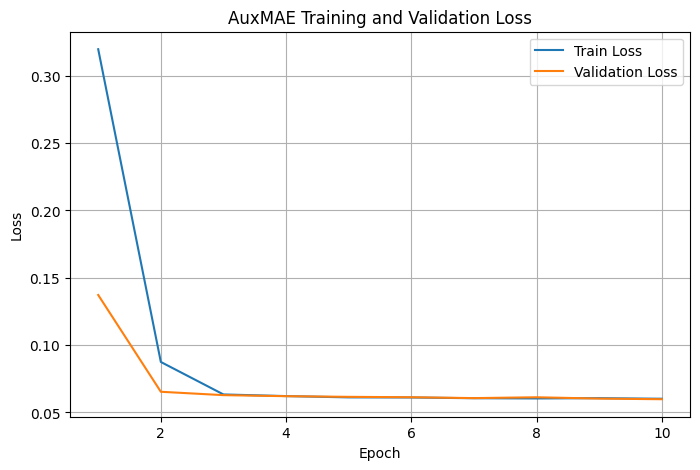

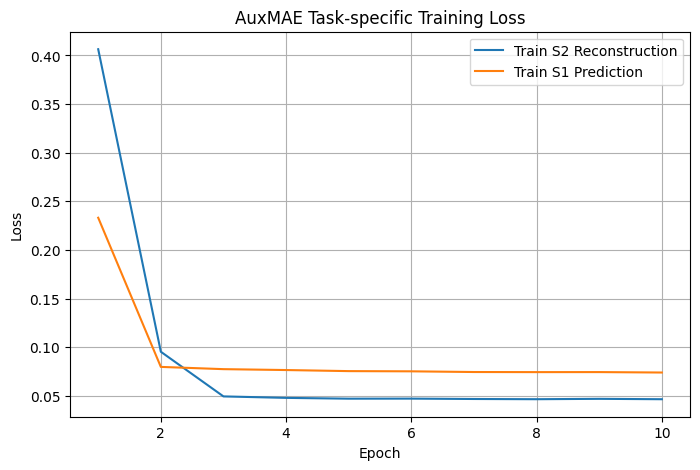

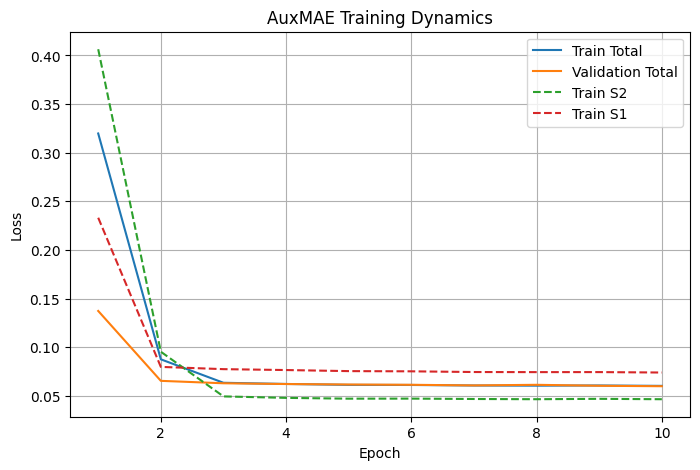

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# Load saved arrays (or skip this if already in memory)
train_losses = np.load("auxmae_train_losses_4_dec_change.npy")
val_losses = np.load("auxmae_val_losses_4_dec_change.npy")
train_s2_losses = np.load("auxmae_train_s2_losses_4_dec_change.npy")
train_s1_losses = np.load("auxmae_train_s1_losses_4_dec_change.npy")

epochs = np.arange(1, len(train_losses) + 1)

# Total train vs validation
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AuxMAE Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

# Task-specific training Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_s2_losses, label="Train S2 Reconstruction")
plt.plot(epochs, train_s1_losses, label="Train S1 Prediction")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AuxMAE Task-specific Training Loss")
plt.legend()
plt.grid()
plt.show()

# Combined View
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train Total")
plt.plot(epochs, val_losses, label="Validation Total")
plt.plot(epochs, train_s2_losses, linestyle="--", label="Train S2")
plt.plot(epochs, train_s1_losses, linestyle="--", label="Train S1")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AuxMAE Training Dynamics")
plt.legend()
plt.grid()
plt.show()

In [23]:
checkpoint = torch.load("auxmae_shared_best_4.pt")
    
model.load_state_dict(checkpoint['model'])

<All keys matched successfully>

Loaded model from epoch 15





In [25]:
import matplotlib.pyplot as plt
import torch
import numpy as np

def unpatchify(x, patch_size, h, w):
    B, L, D = x.shape
    C = D // (patch_size ** 2)
    p = patch_size
    
    x = x.reshape(B, h, w, p, p, C)
    x = x.permute(0, 5, 1, 3, 2, 4)
    x = x.reshape(B, C, h * p, w * p)
    return x

def denormalise_s1(s1_tensor, s1_min=-60.0, s1_max=25.0):
    """Converts normalised [0, 1] S1 back to dB scale."""
    return s1_tensor * (s1_max - s1_min) + s1_min

@torch.no_grad()
def test_and_visualise(model, test_loader, device, num_samples=30):
    model.eval()
    
    # Load the best checkpoint
    checkpoint = torch.load(CHECKPOINT_PATH)
    model.load_state_dict(checkpoint['model'])
    print(f"Loaded model from epoch {checkpoint['epoch']}")

    # Get a batch
    s2, s1 = next(iter(test_loader))
    s2, s1 = s2.to(device), s1.to(device)
    
    # Run Task 1: S2 Reconstruction (Masked)
    loss_s2, pred_s2_patches, mask = model(s2, s1, task="s2_reconstruction")

    # Get original patches for reference
    s2_patches_orig = model._image_to_patches(s2) 
    
    # Build composite: original where visible, predicted where masked
    mask_expanded = mask.unsqueeze(-1).expand_as(pred_s2_patches) 
    composite_patches = torch.where(mask_expanded.bool(), pred_s2_patches, s2_patches_orig)
    
    h = w = IMG_SIZE // PATCH_SIZE
    recon_s2 = unpatchify(composite_patches, PATCH_SIZE, h, w)
    
    # Run Task 2: S1 Prediction (From full S2)
    loss_s1, pred_s1_patches, _ = model(s2, s1, task="s1_prediction")

    # Reshape patches back to images
    h = w = IMG_SIZE // PATCH_SIZE
    pred_s1 = unpatchify(pred_s1_patches, PATCH_SIZE, h, w)
    
    # Create the visualisation
    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4 * num_samples))
    
    for i in range(num_samples):
        # Original S2
        orig_s2_img = s2[i, :3].permute(1, 2, 0).cpu().numpy()
        axes[i, 0].imshow(np.clip(orig_s2_img, 0, 1))
        axes[i, 0].set_title("Original S2")

        # Masked S2
        m = mask[i].reshape(h, w).cpu().numpy()
        m_upscaled = np.repeat(np.repeat(m, PATCH_SIZE, axis=0), PATCH_SIZE, axis=1)
        masked_s2 = orig_s2_img.copy()
        masked_s2[m_upscaled == 1] = 0
        axes[i, 1].imshow(masked_s2)
        axes[i, 1].set_title("Masked Input")

        # Reconstructed S2
        recon_s2_img = recon_s2[i, :3].permute(1, 2, 0).cpu().numpy()
        axes[i, 2].imshow(np.clip(recon_s2_img, 0, 1))
        axes[i, 2].set_title("Reconstructed S2")

        # Original S1
        orig_s1_img = s1[i, 0].cpu().numpy()
        axes[i, 3].imshow(orig_s1_img, cmap='gray')
        axes[i, 3].set_title("Target S1 (VV)")

        # Predicted S1 from S2 input
        pred_s1_img = pred_s1[i, 0].cpu().numpy()
        axes[i, 4].imshow(pred_s1_img, cmap='gray')
        axes[i, 4].set_title("Predicted S1")

    plt.tight_layout()
    plt.show()

# Run it
if __name__ == "__main__":
    test_and_visualise(model, val_loader_mae, device)

In [79]:
@torch.no_grad()
def visualise_specific_patch(model, patch_path, device):
    patch_path = "data/mae_patches_all/" + patch_path
    model.eval()
    
    # Load and Preprocess exactly like the dataset class
    with np.load(patch_path) as f:
        img = f["image"].astype(np.float32)

    s2_raw = img[:4]
    s1_raw = img[4:]

    # Normalisation
    s2 = np.clip(s2_raw, 0.0, 1.0)
    s1 = (s1_raw - (-60.0)) / (25.0 - (-60.0))
    s1 = np.clip(s1, 0.0, 1.0)

    s2_tensor = torch.from_numpy(s2).unsqueeze(0).to(device)
    s1_tensor = torch.from_numpy(s1).unsqueeze(0).to(device)

    # Run inference
    # Task 1: S2 reconstruction
    _, pred_s2_patches, mask = model(s2_tensor, s1_tensor, task="s2_reconstruction")
    
    # Task 2: S1 prediction
    _, pred_s1_patches, _ = model(s2_tensor, s1_tensor, task="s1_prediction")

    # Original visible + predicted masked
    s2_patches_orig = model._image_to_patches(s2_tensor)
    mask_expanded = mask.unsqueeze(-1).expand_as(pred_s2_patches)
    composite_patches = torch.where(mask_expanded.bool(), pred_s2_patches, s2_patches_orig)
    
    h = w = IMG_SIZE // MASK_PATCH_SIZE
    recon_s2 = unpatchify(composite_patches, MASK_PATCH_SIZE, h, w)
    pred_s1 = unpatchify(pred_s1_patches, MASK_PATCH_SIZE, h, w)

    # 4. Visualisation (Single Row)
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))
    
    # Original S2
    orig_s2_img = s2_tensor[0, :3].permute(1, 2, 0).cpu().numpy()
    axes[0].imshow(np.clip(orig_s2_img, 0, 1))
    axes[0].set_title(f"Original S2\n{os.path.basename(patch_path)}")

    # Masked S2
    m = mask[0].reshape(h, w).cpu().numpy()
    m_upscaled = np.repeat(np.repeat(m, MASK_PATCH_SIZE, axis=0), MASK_PATCH_SIZE, axis=1)
    masked_s2 = orig_s2_img.copy()
    masked_s2[m_upscaled == 1] = 0
    axes[1].imshow(masked_s2)
    axes[1].set_title("Masked Input")

    # Reconstructed S2
    recon_s2_img = recon_s2[0, :3].permute(1, 2, 0).cpu().numpy()
    axes[2].imshow(np.clip(recon_s2_img, 0, 1))
    axes[2].set_title("Reconstructed S2")

    # Target S1
    orig_s1_img = s1_tensor[0, 0].cpu().numpy()
    axes[3].imshow(orig_s1_img, cmap='gray')
    axes[4].set_title("Target S1")

    # Predicted S1
    pred_s1_img = pred_s1[0, 0].cpu().numpy()
    axes[4].imshow(pred_s1_img, cmap='gray')
    axes[4].set_title("Predicted S1")

    plt.tight_layout()
    plt.show()

In [ ]:
patch_to_test = sorted_patches[2070]
MASK_PATCH_SIZE = 8

print(f"Testing patch: {patch_to_test}")
visualise_specific_patch(model, patch_to_test[0], device)

# Dataset Creation for CNN Training

In [37]:
import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

import os
import math
import json
from pathlib import Path
from tqdm import tqdm
import numpy as np
import rasterio
from rasterio.windows import Window
from rasterio.enums import Resampling
import cv2
import random
import geopandas as gpd
import glob

from sklearn.model_selection import train_test_split
import tensorflow as tf

from tqdm import tqdm
from scipy.ndimage import distance_transform_edt
from rasterio.features import rasterize

import h5py
from scipy.spatial import cKDTree
from multiprocessing import Pool, cpu_count
from functools import partial
import torch

In [38]:
# Define path locations
DRIVE_BASE = 'data/'

IMG_PATH_2019_WET = os.path.join(DRIVE_BASE, "realigned_images/2019_wet_aligned.tif")
IMG_PATH_2019_DRY = os.path.join(DRIVE_BASE, "realigned_images/2019_dry_aligned.tif")
S1_PATH_2019_DRY = os.path.join(DRIVE_BASE, "realigned_images/2019_S1_SAR_VV_VH.tif")
IMG_PATH_2024 = os.path.join(DRIVE_BASE, "realigned_images/2024_dry_aligned.tif")

LULC_PATH_2019 = os.path.join(DRIVE_BASE, "lulc/senegal_esri_lulc_2019.tif")
LULC_PATH_2024 = os.path.join(DRIVE_BASE, "lulc/senegal_esri_lulc_2024_aligned.tif")

PATCHES_OUT_DIR = os.path.join(DRIVE_BASE, "patches")
os.makedirs(PATCHES_OUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [51]:
# Define constants for splitting into patches of PATCH_SIZE by PATCH_SIZE
CNN_PATCH_SIZE = 64
MIN_URBAN_FRAC = 0.5
STRIDE = 32
SCALE = 10000.0

# Bands selection (1-based indices in geotiff)
# R G B NIR are 1,2,3, 4 respectively
BANDS = [1, 2, 3, 4]

URBAN_CLASS = 7

NUM_LULC_CLASSES = 12

# Random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [40]:
# LULC class mapping
LULC_CLASSES = {
    0: "Nothing (No data)",
    1: "Water",
    2: "Trees",
    4: "Flooded vegetation",
    5: "Crops",
    7: "Built area (Urban)",
    8: "Bare ground",
    9: "Snow / Ice",
    10: "Clouds",
    11: "Rangeland"
}

LULC_COLORS = {
    0: "#000000", # black
    1: "#1f78b4", # blue
    2: "#33a02c", # green
    4: "#6baed6", # light blue
    5: "#ff7f00", # orange
    7: "#e31a1c", # red (urban)
    8: "#b15928", # brown
    9: "#f0f0f0", # white/grey
    10: "#bdbdbd", # grey
    11: "#cab2d6", # purple-ish
}

lulc_cmap = mcolors.ListedColormap(
    [LULC_COLORS[k] for k in sorted(LULC_COLORS.keys())]
)

lulc_norm = mcolors.BoundaryNorm(
    boundaries=list(sorted(LULC_COLORS.keys())) + [max(LULC_COLORS.keys()) + 1],
    ncolors=len(LULC_COLORS)
)

In [41]:
N_MAE_OUT_CHANNELS = 1
MAE_PATCH_SIZE = 4

In [42]:
auxmae_model = AuxMAE().to(device)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
auxmae_model.load_state_dict(checkpoint["model"])
auxmae_model.eval()
print(f"AuxMAE loaded from epoch {checkpoint['epoch']} | val loss: {checkpoint['val_loss']:.6f}")

AuxMAE loaded from epoch 15 | val loss: 0.036761


In [43]:
def extract_auxmae_features(s2_patch, s1_patch, model, device, patch_size, img_size):
    """
    Extracts AuxMAE S1 predictions (from S2 input).
    """

    # Convert to CHW
    s2_raw = np.transpose(s2_patch, (2, 0, 1)).astype(np.float32)
    s1_raw = np.transpose(s1_patch, (2, 0, 1)).astype(np.float32)

    # Normalise S2
    if s2_raw.max() > 10.0:
        s2_raw = s2_raw / 10000.0

    # Normalise S1 (same as training)
    S1_MIN, S1_MAX = -60.0, 25.0
    s1_raw = np.clip((s1_raw - S1_MIN) / (S1_MAX - S1_MIN), 0.0, 1.0)

    with torch.no_grad():
        s2 = torch.tensor(s2_raw).unsqueeze(0).to(device)
        s1 = torch.tensor(s1_raw).unsqueeze(0).to(device)

        # USE S1 PREDICTION TASK
        _, pred_s1_patches, _ = model(s2, s1, task="s1_prediction")

        h = img_size // patch_size

        pred_s1 = pred_s1_patches.reshape(
            1, h, h, patch_size, patch_size, s1.shape[1]
        )
        pred_s1 = pred_s1.permute(0, 5, 1, 3, 2, 4)
        pred_s1 = pred_s1.reshape(1, s1.shape[1], img_size, img_size)

    return pred_s1.squeeze(0).cpu().numpy()

In [18]:
def unpatchify(x, patch_size, h, w):
    """
    x: (B, L, Patch_dim) -> (B, C, H, W)
    """
    B, L, D = x.shape
    C = D // (patch_size ** 2)
    p = patch_size
    
    x = x.reshape(B, h, w, p, p, C)
    x = x.permute(0, 5, 1, 3, 2, 4)
    x = x.reshape(B, C, h * p, w * p)
    return x

# Feature Extraction & Testing Function 
@torch.no_grad()
def test_and_visualise_auxmae_features(model, patch_path, device, embed_dim=256, patch_size=8, img_size=64):
    """
    Visualises the internal latent features of the encoder against the original S2 image,
    the composite reconstruction, and the S1 target.
    """
    model.eval()
    
    # Check constants match model architecture
    assert model.embed_dim == embed_dim, f"Model embed_dim ({model.embed_dim}) does not match specified embed_dim ({embed_dim})"
    assert model.patch_size == patch_size, f"Model patch_size ({model.patch_size}) does not match specified patch_size ({patch_size})"

    print(f"--- Testing AuxMAE Features ---")
    print(f"Patch: {os.path.basename(patch_path)}")
    print(f"Configuration: {img_size}x{img_size} image, {patch_size}x{patch_size} patches, {embed_dim} embed dim.")

    # 1. Load and Normalise Patch exactly like Training
    try:
        with np.load(patch_path) as f:
            img = f["image"].astype(np.float32)
    except FileNotFoundError:
        print(f"Error: File not found at {patch_path}")
        return

    s2_raw = img[:4] # 4 channels for S2
    s1_raw = img[4:] # 2 channels for S1

    # Apply specific normalisation
    s2_norm = np.clip(s2_raw, 0.0, 1.0)
    s1_norm = (s1_raw - (-60.0)) / (25.0 - (-60.0))
    s1_norm = np.clip(s1_norm, 0.0, 1.0)

    # Convert to tensors and move to device
    s2_tensor = torch.from_numpy(s2_norm).unsqueeze(0).to(device)
    s1_tensor = torch.from_numpy(s1_norm).unsqueeze(0).to(device)

    # Extract latent features w/o masking
    patches = model._image_to_patches(s2_tensor, patch_size)
    tokens = model.s2_patch_embed(patches) + model.pos_embed
    encoded_features = model._run_encoder(tokens)

    # Convert features to spatial grid for vis
    B, L, D = encoded_features.shape
    h_feat = w_feat = img_size // patch_size # (64 // 8) = 8
    cnn_input_features = encoded_features.transpose(1, 2).reshape(B, D, h_feat, w_feat)

    # Generate task outputs for visual comparison
    # Task 1: Masked S2 reconstruction
    _, pred_s2_patches, mask = model(s2_tensor, s1_tensor, task="s2_reconstruction")
    
    # Task 2: S1 prediction
    _, pred_s1_patches, _ = model(s2_tensor, s1_tensor, task="s1_prediction")

    # 4. Build composite S2 img
    mask_expanded = mask.unsqueeze(-1).expand_as(pred_s2_patches)
    composite_patches = torch.where(mask_expanded.bool(), pred_s2_patches, patches)
    
    recon_h = recon_w = img_size // patch_size
    recon_s2 = unpatchify(composite_patches, patch_size, recon_h, recon_w)
    pred_s1 = unpatchify(pred_s1_patches, patch_size, recon_h, recon_w)

    # 5. Visualisation
    fig, axes = plt.subplots(1, 6, figsize=(24, 4))
    
    # titles for columns
    titles = [
        "Original S2", 
        "Masked S2 Input", 
        "Composite S2 Reconstruction", 
        "Latent Feature Heatmap\n(Mean Activation)", 
        "Target S1", 
        "Predicted S1"
    ]

    # Display Original S2 RGB (Channels 0, 1, 2)
    orig_rgb = s2_tensor[0, :3].permute(1, 2, 0).cpu().numpy()
    axes[0].imshow(np.clip(orig_rgb, 0, 1))

    # Masked S2 Input (what the encoder saw during reconstruction task)
    m = mask[0].reshape(recon_h, recon_w).cpu().numpy()
    m_upscaled = np.repeat(np.repeat(m, patch_size, axis=0), patch_size, axis=1)
    masked_view = orig_rgb.copy()
    masked_view[m_upscaled == 1] = 0 # Black out masked patches
    axes[1].imshow(np.clip(masked_view, 0, 1))

    # Composite S2 Reconstruction (Original + Hallucinated)
    recon_rgb = recon_s2[0, :3].permute(1, 2, 0).cpu().numpy()
    axes[2].imshow(np.clip(recon_rgb, 0, 1))

    # Latent Feature Heatmap (Averaged across 256 embedding dimensions)
    # This visualises the spatial attention/activation strength.
    feat_map = torch.mean(cnn_input_features[0], dim=0).cpu().numpy()
    # Interpolate to magma colormap to show intensity clearly
    im_feat = axes[3].imshow(feat_map, cmap='magma')
    fig.colorbar(im_feat, ax=axes[3], fraction=0.046, pad=0.04)

    # Target S1 VV channel (Normalised [0,1])
    # Showing as gray to represent radar intensity correctly
    orig_s1_vv = s1_tensor[0, 0].cpu().numpy()
    axes[4].imshow(orig_s1_vv, cmap='gray', vmin=0, vmax=1)

    # Predicted S1 VV channel (Normalised [0,1])
    pred_s1_vv = pred_s1[0, 0].cpu().numpy()
    axes[5].imshow(pred_s1_vv, cmap='gray', vmin=0, vmax=1)

    # Cleanup formatting
    for ax, title in zip(axes, titles):
        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()
    
    print(f"Feature Map Spatial Grid: {h_feat}x{w_feat}")
    print(f"Extraction complete. Use 'cnn_input_features' for downstream training.")


if __name__ == "__main__":
    # Ensure constants used are defined globally as well if needed
    EMBED_DIM = 256
    PATCH_SIZE = 8
    IMG_SIZE = 64
    CHECKPOINT_PATH = "auxmae_best.pt"
    
    # 1. Initialise the Model (assuming defined elsewhere, e.g., model = AuxMAE(...))
    # model.to(device)
    
    # 2. Load the checkpoing
    try:
        checkpoint = torch.load(CHECKPOINT_PATH)
        model.load_state_dict(checkpoint['model'])
        print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")
    except FileNotFoundError:
        print(f"Checkpoint not found at {CHECKPOINT_PATH}. Visualisation will use untrained model.")

    # 3. Choose a specific patch (e.g., from your sorted urban ratio list)
    # patch_path = sorted_patches[5]
    patch_path = "path_to_a_specific_patch.npz" # Update this to an existing patch!

    # 4. Run the test
    test_and_visualise_auxmae_features(
        model, 
        patch_path, 
        device, 
        embed_dim=EMBED_DIM, 
        patch_size=PATCH_SIZE, 
        img_size=IMG_SIZE
    )

Checkpoint not found at auxmae_best_8.pt. Visualization will use untrained model.


In [20]:
def extract_auxmae_features(s2_patch, s1_patch, model, device, patch_size, img_size):
    """
    Extracts AuxMAE encoder features for a single S2 patch.
    Uses encode_s2_only so no S1 is needed at inference time.

    returns: numpy (n_out, H, W)
    """
    s2_raw = np.transpose(s2_patch, (2, 0, 1)).astype(np.float32)
    s1_raw = np.transpose(s1_patch, (2, 0, 1)).astype(np.float32)
    
    if s2_raw.max() > 10.0:
        s2_raw = s2_raw / 10000.0

    # Normalise S1 to match training normalisation
    S1_MIN, S1_MAX = -60.0, 25.0
    s1_raw = np.clip((s1_raw - S1_MIN) / (S1_MAX - S1_MIN), 0.0, 1.0)

    with torch.no_grad():
        s2 = torch.tensor(s2_raw).unsqueeze(0).to(device)
        s1 = torch.tensor(s1_raw).unsqueeze(0).to(device)
        
        # Full forward pass - S1 guides S2 reconstruction via cross-attention
        # mask is random but that's fine since we save to disk once
        _, pred_pixels, masked_indices, rand_indices = model(s2, s1)

        # Reconstruct full patch sequence: visible = original, masked = predicted
        s2_patches = model._image_to_patches(s2, model.patch_size)[0] # (N, patch_dim)
        full_patches = s2_patches.clone()
        full_patches[masked_indices[0]] = pred_pixels[0]

        # Reshape to spatial image
        h = img_size // patch_size
        n_patches = h * h
        reconstruction = full_patches.reshape(h, h, patch_size, patch_size, 4)
        reconstruction = reconstruction.permute(4, 0, 2, 1, 3).reshape(4, img_size, img_size) # (4, H, W)

    return reconstruction.cpu().numpy()


print("extract_auxmae_features defined.")
# print(f"CNN input channels: 16 existing + {N_OUT_CHANNELS} AuxMAE = {16 + N_OUT_CHANNELS} total")

extract_auxmae_features defined.


In [52]:
BLOCK_ROWS = 512

def extract_patches_from_block(
    dry_block,
    wet_block,
    s1_block,
    lulc_2019_block,
    lulc_2024_block,
    school_dist_block,
    airport_dist_block,
    patch_size,
    stride,
    global_row_offset,
    saved_counter,
    auxmae_model,
    device,
):
    H, W, _ = dry_block.shape
    img_size = patch_size

    for r in range(0, H - patch_size + 1, stride):
        for c in range(0, W - patch_size + 1, stride):

            # Get lulc patches
            lulc_2019_patch = lulc_2019_block[r:r+patch_size, c:c+patch_size]
            lulc_2024_patch = lulc_2024_block[r:r+patch_size, c:c+patch_size]

            # If patch contains 'None' then don't use it as part of our data
            if np.any(lulc_2019_patch == 0):
                continue
            
            # Classify this patch, and randomly keep non-urban patches
            is_urban = np.any(lulc_2019_patch == URBAN_CLASS)
            if not is_urban:
                NON_URBAN_KEEP_PROB = 0.05
                if random.random() > NON_URBAN_KEEP_PROB:
                    continue

            # Get s2 and s1 patches
            dry_patch = dry_block[r:r+patch_size, c:c+patch_size, :]
            wet_patch = wet_block[r:r+patch_size, c:c+patch_size, :]
            s1_patch = s1_block[r:r+patch_size, c:c+patch_size, :]

            school_patch = school_dist_block[r:r+patch_size, c:c+patch_size, :]

            airport_patch = airport_dist_block[
                r:r+patch_size, c:c+patch_size, :
            ]

            patch = np.concatenate([
                np.transpose(dry_patch, (2, 0, 1)),
                np.transpose(wet_patch, (2, 0, 1)),
                lulc_2019_patch[None, :, :],
                lulc_2024_patch[None, :, :],
                np.transpose(school_patch, (2, 0, 1)),
                np.transpose(airport_patch, (2, 0, 1)),
            ], axis=0)

            # Add AuxMAE features
            auxmae_features = extract_auxmae_features(
                s2_patch=dry_patch, # we trained auxmae using the dry as s2_patch
                s1_patch=s1_patch,
                model=auxmae_model,
                device=device,
                patch_size=auxmae_model.patch_size,
                img_size=64,
            )

            # Stack features onto other channels
            patch = np.concatenate([patch, auxmae_features], axis=0)

            # Sanity check
            # assert patch.shape[0] == 16 + N_MAE_OUT_CHANNELS
            
            out_path = os.path.join(
                PATCHES_OUT_DIR,
                f"patch_r{global_row_offset+r}_c{c}_urban.npz"
            )

            np.savez_compressed(out_path, x=patch)
            saved_counter += 1

    return saved_counter


# Block-wise extraction and saving (to avoid memory issues)
def extract_and_save_patches_blockwise(
    img_dry_path,
    img_wet_path,
    s1_path,
    lulc_2019_path,
    lulc_2024_path,
    school_dists_array,
    airport_dists_array,
    patch_size,
    stride,
    block_rows,
    auxmae_model,
):
    saved = 0

    with rasterio.open(img_dry_path) as dry_ds, \
         rasterio.open(img_wet_path) as wet_ds, \
         rasterio.open(s1_path) as s1_ds, \
         rasterio.open(lulc_2019_path) as lulc_ds_2019, \
         rasterio.open(lulc_2024_path) as lulc_ds_2024:

        H, W = dry_ds.height, dry_ds.width

        assert dry_ds.count >= 4
        assert wet_ds.count >= 4

        print(f"Raster size: {H} x {W}")
        print("Starting blockwise extraction...")

        for row0 in tqdm(range(0, H, block_rows), desc="Blocks"):
            row1 = min(row0 + block_rows + patch_size, H)

            win = Window(
                col_off=0,
                row_off=row0,
                width=W,
                height=row1 - row0
            )

            #  Read rasters (aligned windows)
            dry_block = np.stack(
                [dry_ds.read(b, window=win) for b in (1, 2, 3, 4)],
                axis=-1
            )

            wet_block = np.stack(
                [wet_ds.read(b, window=win) for b in (1, 2, 3, 4)],
                axis=-1
            )

            s1_block = np.stack(
                [s1_ds.read(1, window=win)],
                axis=-1
            )

            lulc_2019_block = lulc_ds_2019.read(1, window=win)
            lulc_2024_block = lulc_ds_2024.read(1, window=win)

            # Distance blocks (already aligned)
            school_block = school_dists_array[row0:row1, :, :]
            airport_block = airport_dists_array[row0:row1, :, :]

            saved = extract_patches_from_block(
                dry_block,
                wet_block,
                s1_block,
                lulc_2019_block,
                lulc_2024_block,
                school_block,
                airport_block,
                patch_size,
                stride,
                global_row_offset=row0,
                saved_counter=saved,
                auxmae_model=auxmae_model,
                device=device,
            )

    print(f"\n Saved {saved} patches to {PATCHES_OUT_DIR}")

In [53]:
school_dists_array = np.load(
    "data/preprocessed_data/school_distances.npy",
    mmap_mode="r"
)

airport_dists_array = np.load(
    "data/preprocessed_data/airport_distances.npy",
    mmap_mode="r"
)

extract_and_save_patches_blockwise(
    img_dry_path=IMG_PATH_2019_DRY,
    img_wet_path=IMG_PATH_2019_WET,
    s1_path=S1_PATH_2019_DRY,
    lulc_2019_path=LULC_PATH_2019,
    lulc_2024_path=LULC_PATH_2024,
    school_dists_array=school_dists_array,
    airport_dists_array=airport_dists_array,
    patch_size=CNN_PATCH_SIZE,
    stride=STRIDE,
    block_rows=BLOCK_ROWS,
    auxmae_model=auxmae_model,
)

Raster size: 51867 x 70964
Starting blockwise extraction...



 Saved 221719 patches to data/patches


In [55]:
def normalise_rgb(img_chw):
    """
    img_chw: (3, H, W)
    returns: (H, W, 3) in [0,1]
    """
    rgb = np.stack([img_chw[0], img_chw[1], img_chw[2]], axis=-1)
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min() + 1e-6)
    return rgb

def compute_ndvi(red, nir):
    red = red.astype(np.float32)
    nir = nir.astype(np.float32)
    return (nir - red) / (nir + red + 1e-6)

Found 214387 patches
data/patches\patch_r14720_c47904_urban.npz
Patch shape: (17, 64, 64)


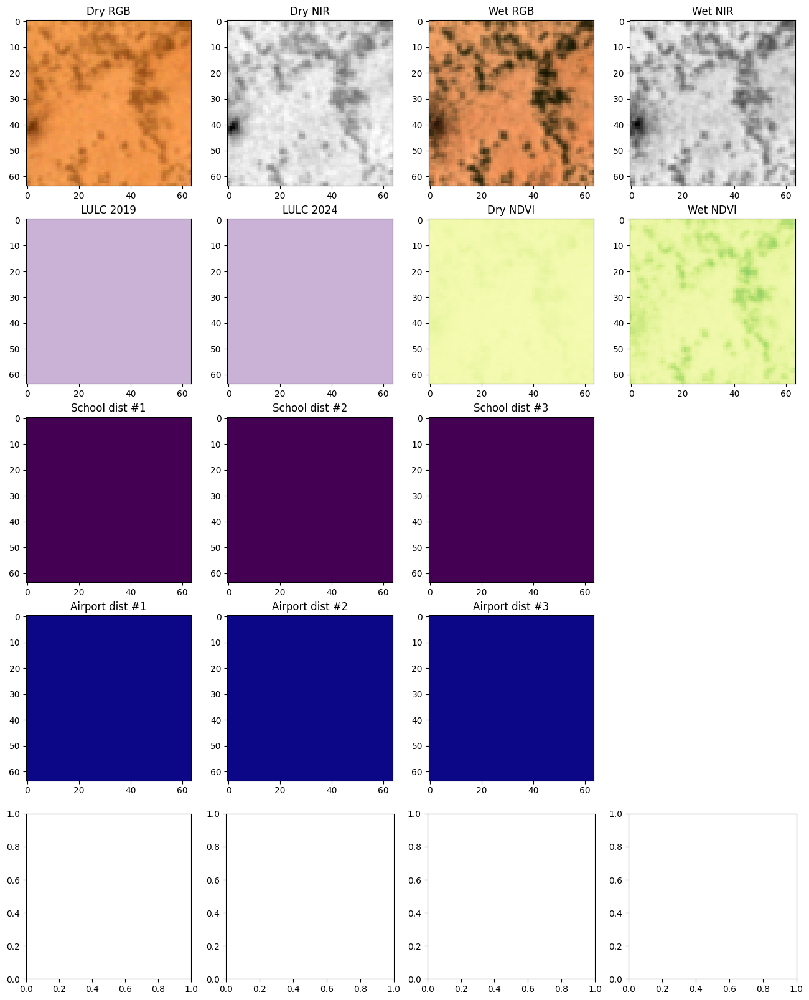

In [56]:
patch_files = glob.glob("data/patches/*.npz")
print(f"Found {len(patch_files)} patches")
patch_path = patch_files[12930]
print(patch_path)
data = np.load(patch_path)
patch = data["x"]
print("Patch shape:", patch.shape)

dry = patch[0:4]
wet = patch[4:8]
lulc_2019 = patch[8]
lulc_2024 = patch[9]
school = patch[10:13]
airport = patch[13:16]
auxmae = patch[16:]

fig, axes = plt.subplots(5, 4, figsize=(16, 20))
axes = axes.ravel()

dry_rgb = normalise_rgb(dry[0:3])
axes[0].imshow(dry_rgb)
axes[0].set_title("Dry RGB")
axes[1].imshow(dry[3], cmap="gray")
axes[1].set_title("Dry NIR")
wet_rgb = normalise_rgb(wet[0:3])
axes[2].imshow(wet_rgb)
axes[2].set_title("Wet RGB")
axes[3].imshow(wet[3], cmap="gray")
axes[3].set_title("Wet NIR")

axes[4].imshow(lulc_2019, cmap=lulc_cmap, norm=lulc_norm)
axes[4].set_title("LULC 2019")
axes[5].imshow(lulc_2024, cmap=lulc_cmap, norm=lulc_norm)
axes[5].set_title("LULC 2024")
dry_ndvi = compute_ndvi(dry[0], dry[3])
wet_ndvi = compute_ndvi(wet[0], wet[3])
axes[6].imshow(dry_ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[6].set_title("Dry NDVI")
axes[7].imshow(wet_ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[7].set_title("Wet NDVI")

for i in range(3):
    axes[8 + i].imshow(school[i], cmap="viridis")
    axes[8 + i].set_title(f"School dist #{i+1}")
axes[11].axis("off")

for i in range(3):
    axes[12 + i].imshow(airport[i], cmap="plasma")
    axes[12 + i].set_title(f"Airport dist #{i+1}")
axes[15].axis("off")

# AuxMAE reconstruction — display as RGB + NIR since it's in S2 band space
vmin = np.percentile(auxmae[:3], 2)
vmax = np.percentile(auxmae[:3], 98)
# auxmae_rgb = np.clip(auxmae[:3].transpose(1, 2, 0), vmin, vmax)
auxmae_rgb = (auxmae[:3])
# auxmae_rgb = (auxmae_rgb - vmin) / (vmax - vmin + 1e-6)

axes[16].imshow(auxmae_rgb)
axes[16].set_title("AuxMAE RGB (S1-guided recon)")

axes[17].imshow(auxmae[3], cmap="gray")
axes[17].set_title("AuxMAE NIR (S1-guided recon)")

auxmae_ndvi = compute_ndvi(auxmae[0], auxmae[3])
axes[18].imshow(auxmae_ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
axes[18].set_title("AuxMAE NDVI")

# Difference between dry input and AuxMAE reconstruction
diff_rgb = auxmae_rgb - normalise_rgb(dry[0:3])
axes[19].imshow(diff_rgb, cmap="RdBu", vmin=-0.5, vmax=0.5)
axes[19].set_title("AuxMAE - Dry RGB diff")

lulc_legend = [
    mpatches.Patch(color=LULC_COLORS[k], label=LULC_CLASSES[k])
    for k in sorted(LULC_COLORS.keys())
]
fig.legend(
    handles=lulc_legend,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=5,
    fontsize=8,
    title="LULC classes",
    title_fontsize=9,
    framealpha=0.8,
)

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"All {patch.shape[0]} channels - {os.path.basename(patch_path)}",
    fontsize=13
)
plt.tight_layout()
plt.savefig("patch_all_channels.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> patch_all_channels.png")

AuxMAE feature variation across patches:
Patch                                F1 mean  F2 mean  F3 mean  F4 mean
patch_r46176_c50944_urban.npz          0.075    0.041    0.006   -0.087
patch_r24320_c17952_urban.npz         -0.076   -0.011    0.047   -0.012
patch_r22592_c59296_urban.npz         -0.163    0.121    0.125    0.011
patch_r15072_c20736_urban.npz         -0.222    0.044    0.033    0.006
patch_r21504_c20640_urban.npz         -0.080   -0.033    0.020    0.110
patch_r32480_c37824_urban.npz         -0.054    0.071    0.097   -0.015
patch_r47648_c22304_urban.npz          0.110   -0.078   -0.064   -0.081
patch_r34784_c15424_urban.npz          0.038   -0.066   -0.155    0.123


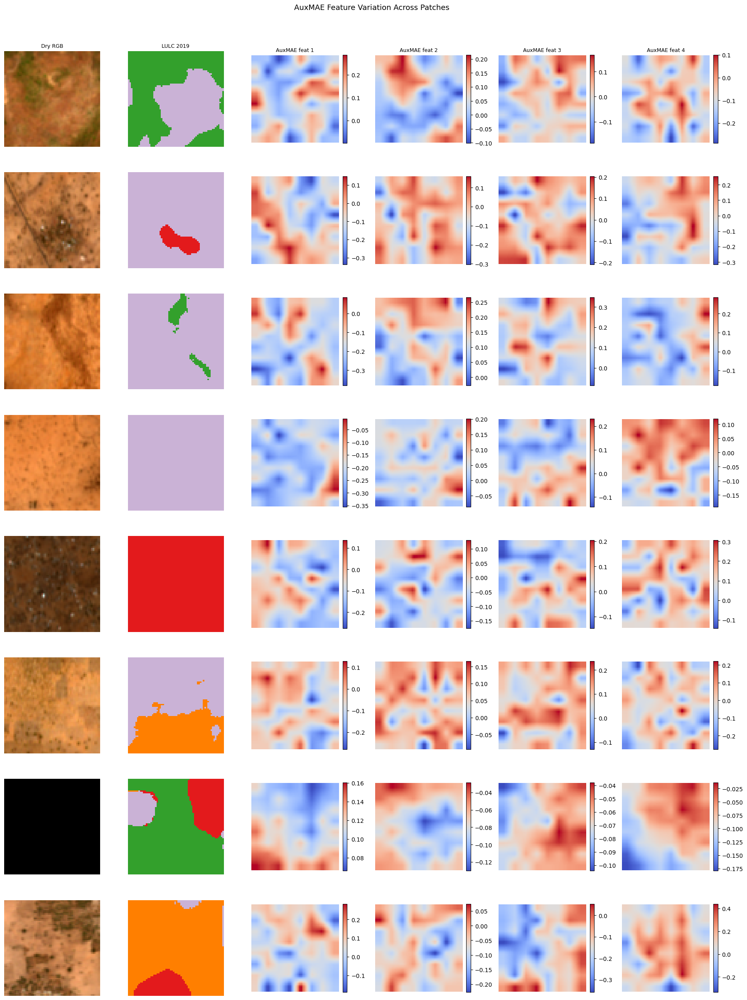

Saved -> auxmae_variation.png


In [35]:
import random

patch_files = sorted(glob.glob("data/patches/*.npz"))
sample_paths = random.sample(patch_files, 8)

fig, axes = plt.subplots(8, 6, figsize=(18, 24))

col_titles = ["Dry RGB", "LULC 2019", "AuxMAE feat 1", "AuxMAE feat 2", "AuxMAE feat 3", "AuxMAE feat 4"]
for j, title in enumerate(col_titles):
    axes[0, j].set_title(title, fontsize=9)

for i, fpath in enumerate(sample_paths):
    data = np.load(fpath)
    patch = data["x"]

    dry = patch[0:4]
    lulc_2019 = patch[8]
    auxmae = patch[16:20]

    dry_rgb = normalise_rgb(dry[0:3])
    axes[i, 0].imshow(dry_rgb)
    axes[i, 0].set_ylabel(os.path.basename(fpath)[:20], fontsize=6)

    axes[i, 1].imshow(lulc_2019, cmap=lulc_cmap, norm=lulc_norm)

    for j in range(4):
        im = axes[i, 2 + j].imshow(auxmae[j], cmap="coolwarm")
        axes[i, 2 + j].set_xlabel(
            f"[{auxmae[j].min():.2f}, {auxmae[j].max():.2f}]", fontsize=6
        )
        plt.colorbar(im, ax=axes[i, 2 + j], fraction=0.046, pad=0.04)

    for j in range(6):
        axes[i, j].axis("off")

# Print value stats to confirm variation
print("AuxMAE feature variation across patches:")
print(f"{'Patch':<35} {'F1 mean':>8} {'F2 mean':>8} {'F3 mean':>8} {'F4 mean':>8}")
for fpath in sample_paths:
    patch = np.load(fpath)["x"]
    auxmae = patch[16:20]
    means = [auxmae[j].mean() for j in range(4)]
    print(f"{os.path.basename(fpath)[:35]:<35} {means[0]:>8.3f} {means[1]:>8.3f} {means[2]:>8.3f} {means[3]:>8.3f}")

plt.suptitle("AuxMAE Feature Variation Across Patches", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("auxmae_variation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> auxmae_variation.png")

In [164]:
# Run this on 3 different patches to see if the encoder itself is varying
model.eval()

for fpath in random.sample(all_patches, 3):
    data  = np.load(fpath)
    patch = data["x"].astype(np.float32)

    s2_raw = patch[0:4]
    if s2_raw.max() > 10.0:
        s2_raw = s2_raw / 10000.0

    with torch.no_grad():
        s2        = torch.tensor(s2_raw).unsqueeze(0).to(device)
        s2_tokens = model.patch_embed.s2_embed(s2)
        s2_tokens = s2_tokens.flatten(2).transpose(1, 2)
        pe        = model._get_pos_embed(s2_tokens.shape[1], s2_tokens.device)
        s2_tokens = s2_tokens + pe
        encoded   = model.encoder(s2_tokens)   # (1, N, D)

    print(f"{os.path.basename(fpath)}")
    print(f"  encoded mean : {encoded.mean().item():.4f}")
    print(f"  encoded std  : {encoded.std().item():.4f}")
    print(f"  encoded min  : {encoded.min().item():.4f}")
    print(f"  encoded max  : {encoded.max().item():.4f}")
    print()

patch_r45568_c54112_urban.npz
  encoded mean : 0.0193
  encoded std  : 0.8559
  encoded min  : -2.0575
  encoded max  : 2.1165

patch_r24672_c57280_urban.npz
  encoded mean : 0.0192
  encoded std  : 0.8576
  encoded min  : -2.0784
  encoded max  : 2.1428

patch_r11136_c15872_urban.npz
  encoded mean : 0.0194
  encoded std  : 0.8581
  encoded min  : -2.0824
  encoded max  : 2.1275



In [166]:
# Load checkpoint and verify weights moved from random init
checkpoint = torch.load("mixmae_best.pt", map_location=device)

# Check a few encoder weight norms — if near 1.0 uniformly, 
# weights may not have updated much
for name, param in model.encoder.named_parameters():
    if "weight" in name and param.dim() > 1:
        print(f"{name}: norm={param.norm().item():.4f}, "
              f"std={param.std().item():.4f}")
        break   # just check first layer

layers.0.self_attn.in_proj_weight: norm=24.9251, std=0.0562


In [170]:
# Check a few MAE patches to see if values were normalised
mae_patches = sorted(glob.glob(os.path.join("data/mae_patches_all", "*.npz")))
print(len(mae_patches))
for fpath in mae_patches:
    img = np.load(fpath)["image"].astype(np.float32)
    s2  = img[:4]
    s1  = img[4:]
    print(f"{os.path.basename(fpath)}")
    print(f"  S2 range: [{s2.min():.2f}, {s2.max():.2f}]")
    print(f"  S1 range: [{s1.min():.2f}, {s1.max():.2f}]")
    print()

298464
patch_r0_c10304.npz
  S2 range: [0.00, 0.00]
  S1 range: [-60.00, -60.00]

patch_r0_c10848.npz
  S2 range: [0.00, 0.00]
  S1 range: [-60.00, -60.00]

patch_r0_c11552.npz
... (15933 lines trimmed) ...
  S1 range: [-60.00, -60.00]

patch_r10784_c52704.npz
  S2 range: [0.00, 0.00]
  S1 range: [-60.00, -60.00]

patch_r10784_c53664.npz
  S2 range: [0.00, 0.00]
  S1 range: [-60.00, -60.00]

